# TUBES Kecerdasan Buatan – Kelompok 6
## Household Electricity Load Forecasting: GA + PSO + LSTM + Fuzzy (UCI ID 235)

Notebook ini **mandiri**: tinggal *Run all* (Runtime → Run all) di Google Colab. Dataset dicari/diunduh otomatis.

**Alur:** Dataset UCI → preprocessing → EDA → split kronologis → baseline naif → **A** Baseline LSTM → **GA** (seleksi fitur) → **B** GA+LSTM → **PSO** (hyperparameter) → **C** PSO+LSTM → **D** GA+PSO+LSTM → **Fuzzy (Model E)** → pipeline inference → ekspor artefak untuk Streamlit.

**Sebelum menjalankan penuh:**
1. Ubah `QUICK_MODE = True` di Sel 2 dan *Run all* satu kali (±5–10 menit) untuk memastikan semuanya jalan.
2. Kembalikan ke `False` lalu jalankan penuh. Perkiraan kasar di GPU T4: 1,5–2,5 jam (belum diukur; untuk mempercepat, kurangi `ga_seeds`/`pso_seeds` menjadi 2 dan `final_epochs` menjadi 30). Di CPU jauh lebih lama, jadi gunakan GPU: Runtime → Change runtime type → T4 GPU.
3. Hasil antar-tahap disimpan di folder `cache/`. Jika runtime terputus, jalankan ulang dari awal dan tahap yang sudah selesai akan dilewati (`RESUME = True`).

**Perbaikan dibanding versi lama:** gap data panjang tidak lagi diisi datar, semua model dievaluasi pada target test yang identik, GA/PSO dijalankan beberapa seed (best/mean/std), PSO untuk Model D di-tuning ulang pada fitur hasil GA, ada baseline naif, dan fuzzy dibangun dari persentil data latih.

In [1]:
# SEL 1: ENVIRONMENT, GOOGLE DRIVE (OPSIONAL), DAN DIREKTORI KERJA
import os, sys
from pathlib import Path

USE_DRIVE = True                 # False -> semua output di /content (hilang saat runtime reset)
PROJECT_NAME = 'TUBES_KB_KELOMPOK_6'

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_DIR = None
if IN_COLAB and USE_DRIVE:
    try:
        drive.mount('/content/drive')
        PROJECT_DIR = Path('/content/drive/MyDrive') / PROJECT_NAME
    except Exception as e:
        print('[PERINGATAN] Mount Drive gagal, memakai penyimpanan sementara:', e)
if PROJECT_DIR is None:
    base = Path('/content') if IN_COLAB else Path(os.environ.get('TUBES_DIR', Path.cwd()))
    PROJECT_DIR = base / PROJECT_NAME

DATA_DIR, MODELS_DIR = PROJECT_DIR / 'data', PROJECT_DIR / 'models'
FIG_DIR, CACHE_DIR = MODELS_DIR / 'figures', PROJECT_DIR / 'cache'
for d in (DATA_DIR, MODELS_DIR, FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

print('[OK] Colab        :', IN_COLAB)
print('[OK] Project dir  :', PROJECT_DIR)

[PERINGATAN] Mount Drive gagal, memakai penyimpanan sementara: mount failed
[OK] Colab        : True
[OK] Project dir  : /content/TUBES_KB_KELOMPOK_6


In [2]:
# SEL 2: IMPORT, KONFIGURASI EKSPERIMEN, DAN SEED
import time, json, pickle, random, zipfile, shutil, hashlib, urllib.request, warnings, platform, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

# Membatasi alokasi memori GPU agar tidak crash
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

# ----------------------------- PENGATURAN UTAMA -----------------------------
QUICK_MODE = False     # True = uji cepat (budget sangat kecil, hasil TIDAK untuk laporan)
RESUME = True          # True = lewati tahap yang hasilnya sudah ada di folder cache/
GLOBAL_SEED = 42
TARGET = 'Global_active_power'
SEQ_MIN, SEQ_MAX = 12, 36          # batas pencarian panjang window PSO (jam)
MAX_SEQ = SEQ_MAX                  # dipakai untuk menyamakan target evaluasi semua model

if not QUICK_MODE:
    # Optimasi budget agar stabil di Google Colab Free (seeds = 2, final_epochs = 30)
    cfg = dict(
        ga_pop=10, ga_gen=8, ga_patience=4, ga_seeds=[42, 7], ga_lambda=0.02,
        pso_particles=8, pso_iters=6, pso_w=0.7, pso_c1=1.5, pso_c2=1.5, pso_vmax=0.25,
        pso_seeds=[42, 7],
        proxy_epochs=3, proxy_samples=6000,
        final_epochs=30, final_patience=5, final_seeds=[1, 2])
else:
    cfg = dict(
        ga_pop=4, ga_gen=2, ga_patience=2, ga_seeds=[42], ga_lambda=0.02,
        pso_particles=3, pso_iters=2, pso_w=0.7, pso_c1=1.5, pso_c2=1.5, pso_vmax=0.25,
        pso_seeds=[42],
        proxy_epochs=1, proxy_samples=1500,
        final_epochs=3, final_patience=2, final_seeds=[1])

# Hyperparameter baseline (Model A dan Model B) - tidak dioptimasi
BASE_HP = dict(seq_len=24, units=32, dropout=0.1, lr=1e-3, batch=64)
EVAL_SEED = 42        # seed tetap untuk evaluasi fitness GA / PSO (kandidat sama -> hasil sama)
# -----------------------------------------------------------------------------

def set_seed(s):
    os.environ['PYTHONHASHSEED'] = str(s)
    random.seed(s); np.random.seed(s); keras.utils.set_random_seed(int(s))
set_seed(GLOBAL_SEED)

print('[MODE]', 'QUICK (uji cepat)' if QUICK_MODE else 'PENUH')
print('[VERSI] python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| tensorflow', tf.__version__)
if gpus:
    print('[GPU]', gpus[0].name)
else:
    print('[GPU] TIDAK ADA - training akan lambat. Runtime > Change runtime type > T4 GPU')
print('[CFG]', json.dumps(cfg))

[MODE] PENUH
[VERSI] python 3.13.16 | numpy 2.4.6 | pandas 2.2.3 | tensorflow 2.21.0
[GPU] /physical_device:GPU:0
[CFG] {"ga_pop": 10, "ga_gen": 8, "ga_patience": 4, "ga_seeds": [42, 7], "ga_lambda": 0.02, "pso_particles": 8, "pso_iters": 6, "pso_w": 0.7, "pso_c1": 1.5, "pso_c2": 1.5, "pso_vmax": 0.25, "pso_seeds": [42, 7], "proxy_epochs": 3, "proxy_samples": 6000, "final_epochs": 30, "final_patience": 5, "final_seeds": [1, 2]}


In [3]:
# SEL 3: MENCARI / MENYIAPKAN DATASET (otomatis, tanpa perlu edit path)
RAW_NAME = 'household_power_consumption.txt'
LOCAL_RAW = Path('/content') / RAW_NAME if IN_COLAB else PROJECT_DIR / RAW_NAME
UCI_URL = 'https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip'

def _extract(zip_path, dest_dir):
    with zipfile.ZipFile(zip_path) as zf:
        zf.extract(RAW_NAME, dest_dir)
    return Path(dest_dir) / RAW_NAME

def find_raw_dataset():
    # 0) sudah ada di lokasi kerja
    for p in (LOCAL_RAW, DATA_DIR / RAW_NAME, Path.cwd() / RAW_NAME):
        if p.exists():
            return p
    # 1) .txt / .zip di mana saja di Google Drive (termasuk 'Copy of ...')
    if IN_COLAB and Path('/content/drive/MyDrive').exists():
        drv = Path('/content/drive/MyDrive')
        for p in drv.rglob('*household_power_consumption*.txt'):
            return p
        for z in drv.rglob('*household*.zip'):
            try:
                return _extract(z, LOCAL_RAW.parent)
            except Exception:
                pass
    # 2) unduh dari UCI
    try:
        print('[INFO] Mengunduh dari UCI ...')
        urllib.request.urlretrieve(UCI_URL, str(LOCAL_RAW.parent / 'hpc.zip'))
        return _extract(LOCAL_RAW.parent / 'hpc.zip', LOCAL_RAW.parent)
    except Exception as e:
        print('[INFO] Unduh otomatis gagal:', e)
    # 3) upload manual (.zip atau .txt)
    if IN_COLAB:
        from google.colab import files
        up = files.upload()
        name = list(up.keys())[0]
        if name.endswith('.zip'):
            return _extract(name, LOCAL_RAW.parent)
        shutil.move(name, LOCAL_RAW)
        return LOCAL_RAW
    raise FileNotFoundError('Letakkan household_power_consumption.txt di folder kerja.')

RAW_DATA_PATH = find_raw_dataset()
print(f'[OK] Dataset: {RAW_DATA_PATH} ({RAW_DATA_PATH.stat().st_size/1e6:.1f} MB)')
if IN_COLAB and USE_DRIVE and not (DATA_DIR / RAW_NAME).exists():
    shutil.copy(RAW_DATA_PATH, DATA_DIR / RAW_NAME)      # simpan permanen di Drive
    print('[OK] Salinan disimpan di', DATA_DIR)

[INFO] Mengunduh dari UCI ...
[OK] Dataset: /content/household_power_consumption.txt (133.0 MB)
[OK] Salinan disimpan di /content/TUBES_KB_KELOMPOK_6/data


In [4]:
# SEL 4: MEMBACA DATA MENTAH + ANALISIS MISSING VALUES
t0 = time.time()
df_raw = pd.read_csv(RAW_DATA_PATH, sep=';', na_values=['?', ''], low_memory=False)
df_raw['Datetime'] = pd.to_datetime(df_raw['Date'] + ' ' + df_raw['Time'], format='%d/%m/%Y %H:%M:%S')
df_raw = df_raw.drop(columns=['Date', 'Time']).set_index('Datetime').sort_index().astype('float64')
BASE_COLS = list(df_raw.columns)

print(f'[OK] {len(df_raw):,} baris x {df_raw.shape[1]} kolom ({time.time()-t0:.1f} dtk)')
print('Rentang waktu :', df_raw.index.min(), 's.d.', df_raw.index.max())
exp_min = int((df_raw.index.max() - df_raw.index.min()).total_seconds() // 60) + 1
print(f'Menit seharusnya: {exp_min:,} | menit tercatat: {len(df_raw):,} | timestamp duplikat: {df_raw.index.duplicated().sum()}')

miss = pd.DataFrame({'jumlah_NaN': df_raw.isna().sum(), 'persen': (df_raw.isna().mean() * 100).round(3)})
display(miss)

# Analisis panjang gap (run NaN berurutan) pada kolom target
na = df_raw[TARGET].isna()
grp = (na != na.shift()).cumsum()
gaps = pd.DataFrame({'is_na': na.groupby(grp).first(), 'menit': na.groupby(grp).size(),
                     'mulai': na.index.to_series().groupby(grp).first()})
gaps = gaps[gaps['is_na']].drop(columns='is_na')
short, long_ = gaps[gaps['menit'] <= 60], gaps[gaps['menit'] > 60]
print(f'\nGap pendek (<=60 menit): {len(short)} gap, total {short.menit.sum():,} menit -> diinterpolasi linier')
print(f'Gap panjang (>60 menit) : {len(long_)} gap, total {long_.menit.sum():,} menit -> TIDAK diisi; jendela yang menyentuhnya dibuang')
print('5 gap terpanjang:')
display(gaps.sort_values('menit', ascending=False).head(5))
GAP_STATS = dict(n_short=int(len(short)), min_short=int(short.menit.sum()), n_long=int(len(long_)), min_long=int(long_.menit.sum()),
                 longest_gap_min=int(gaps.menit.max()))

[OK] 2,075,259 baris x 7 kolom (10.5 dtk)
Rentang waktu : 2006-12-16 17:24:00 s.d. 2010-11-26 21:02:00
Menit seharusnya: 2,075,259 | menit tercatat: 2,075,259 | timestamp duplikat: 0


,jumlah_NaN,persen
Global_active_power,25979,1.252
Global_reactive_power,25979,1.252
Voltage,25979,1.252
Global_intensity,25979,1.252
Sub_metering_1,25979,1.252
Sub_metering_2,25979,1.252
Sub_metering_3,25979,1.252



Gap pendek (<=60 menit): 62 gap, total 288 menit -> diinterpolasi linier
Gap panjang (>60 menit) : 9 gap, total 25,691 menit -> TIDAK diisi; jendela yang menyentuhnya dibuang
5 gap terpanjang:


,menit,mulai
Global_active_power,,
138,7226,2010-08-17 21:02:00
140,5237,2010-09-25 03:56:00
14,3723,2007-04-28 00:21:00
100,3305,2009-06-13 00:30:00
118,3129,2010-01-12 14:53:00


### Preprocessing
- Gap pendek (≤60 menit) diinterpolasi linier; **gap panjang tidak diisi**. Cara lama (`bfill/ffill`) membuat segmen datar buatan hingga berhari-hari.
- Agregasi rata-rata per jam. Jam dengan <50% menit valid ditandai `hour_ok = False`. Nilainya hanya diinterpolasi supaya deret tetap kontinu untuk pembuatan lag, tetapi **jendela yang memuat jam bertanda tidak pernah dipakai** untuk training maupun evaluasi.
- Fitur dibangun lewat satu fungsi `build_features()` yang dipakai juga saat inference, sehingga training dan dashboard konsisten.

In [5]:
# SEL 5: INTERPOLASI GAP PENDEK, AGREGASI PER JAM, FEATURE ENGINEERING
# 1) interpolasi hanya untuk gap <= 60 menit
df_f = df_raw.interpolate(method='linear', limit=60, limit_area='inside')
run_len = na.groupby(grp).transform('size')
long_mask = (na & (run_len > 60)).values
df_f.loc[long_mask, :] = np.nan                       # kembalikan gap panjang menjadi NaN

# 2) agregasi per jam (mean mengabaikan NaN) + penanda kualitas jam
hourly_raw = df_f.resample('1h').mean()
valid_frac = df_f[TARGET].notna().resample('1h').mean()
hour_ok = (valid_frac >= 0.5)
hourly = hourly_raw.interpolate(method='linear', limit_direction='both')   # hanya agar deret kontinu

def build_features(base):
    # base: DataFrame per jam dengan 7 kolom UCI asli. Dipakai di training DAN inference.
    d = base[BASE_COLS].copy()
    d['Sub_metering_remainder'] = ((d['Global_active_power'] * 1000.0 / 60.0) -
                                   (d['Sub_metering_1'] + d['Sub_metering_2'] + d['Sub_metering_3'])).clip(lower=0.0)
    g = d[TARGET]
    for k in (1, 2, 3, 24):
        d[f'gap_lag_{k}'] = g.shift(k)
    d['rolling_mean_24h'] = g.shift(1).rolling(24).mean()
    h, dow = d.index.hour, d.index.dayofweek
    d['hour_sin'], d['hour_cos'] = np.sin(2*np.pi*h/24.0), np.cos(2*np.pi*h/24.0)
    d['dow_sin'], d['dow_cos'] = np.sin(2*np.pi*dow/7.0), np.cos(2*np.pi*dow/7.0)
    d['is_weekend'] = (dow >= 5).astype(int)
    return d

df_feat = build_features(hourly)
ok_series = hour_ok.astype(int).rolling(25).min().eq(1)    # baris t layak jika jam t-24..t semuanya ok
mask_valid_rows = df_feat.notna().all(axis=1)
df_clean = df_feat[mask_valid_rows].copy()
ok_arr = ok_series[mask_valid_rows].values.astype(bool)

ALL_FEATURES = list(df_clean.columns)
N_ALL = len(ALL_FEATURES)
print(f'[OK] Data per jam: {len(df_clean):,} baris x {N_ALL} fitur | {df_clean.index.min()} s.d. {df_clean.index.max()}')
print(f'[INFO] Jam bermutu rendah (dekat gap panjang): {(~hour_ok).sum():,} jam; baris tidak layak: {(~ok_arr).sum():,} ({(~ok_arr).mean()*100:.2f}%)')
print('Fitur:', ALL_FEATURES)
display(df_clean[[TARGET]].describe().T)

[OK] Data per jam: 34,565 baris x 18 fitur | 2006-12-17 17:00:00 s.d. 2010-11-26 21:00:00
[INFO] Jam bermutu rendah (dekat gap panjang): 427 jam; baris tidak layak: 643 (1.86%)
Fitur: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Sub_metering_remainder', 'gap_lag_1', 'gap_lag_2', 'gap_lag_3', 'gap_lag_24', 'rolling_mean_24h', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend']


,count,mean,std,min,25%,50%,75%,max
Global_active_power,34565.0,1.091497,0.895058,0.124,0.343367,0.8054,1.577267,6.560533


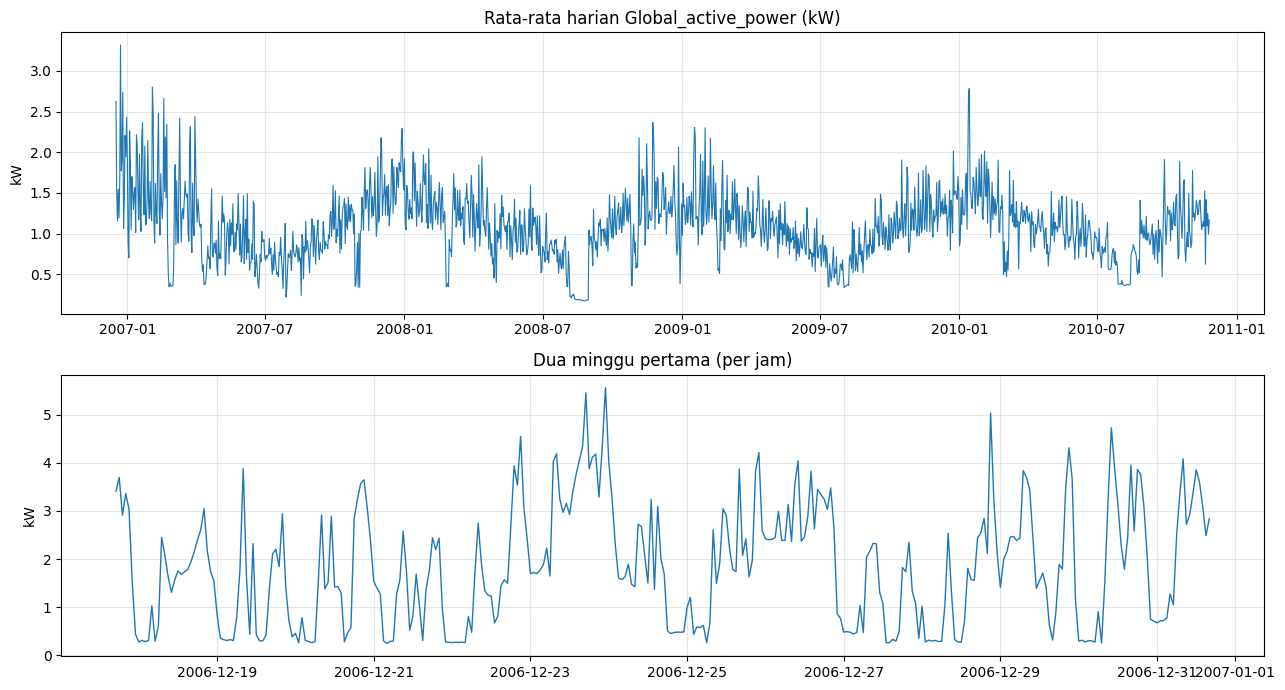

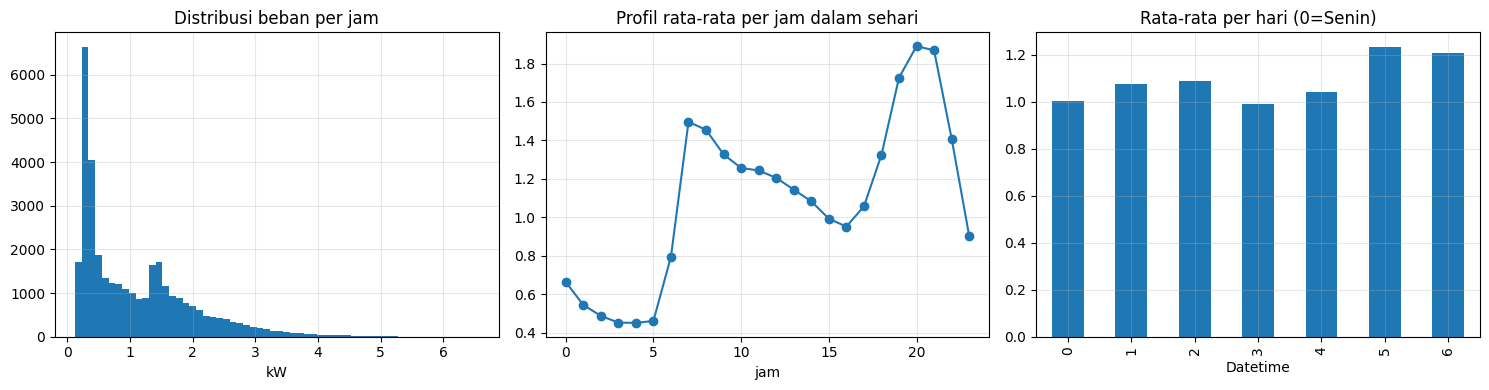

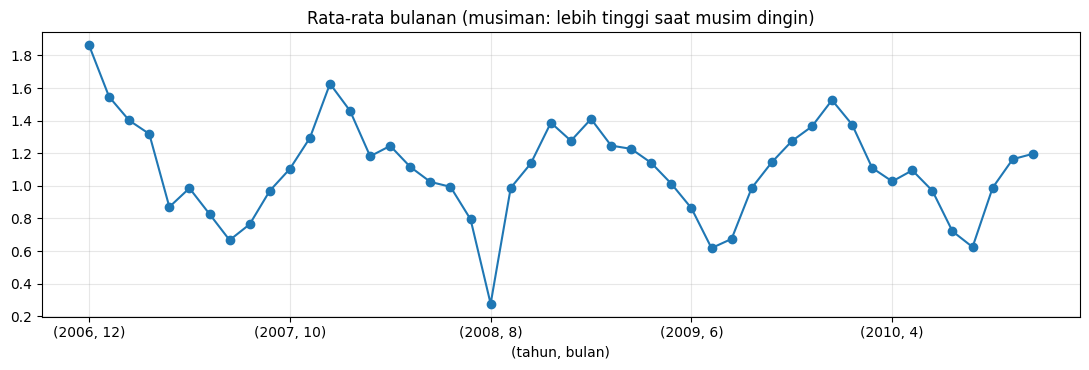

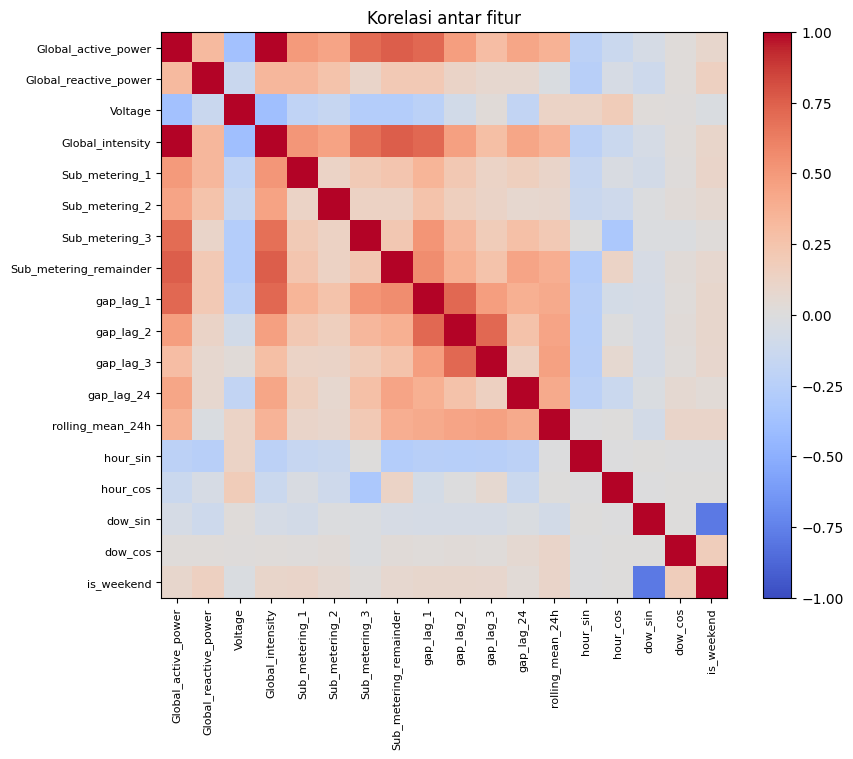

Korelasi tertinggi dengan target:


,corr
Global_intensity,0.999425
Sub_metering_remainder,0.754381
gap_lag_1,0.715487
Sub_metering_3,0.696224
Sub_metering_1,0.499951
gap_lag_2,0.469213
Sub_metering_2,0.439821
gap_lag_24,0.436219


In [6]:
# SEL 6: EDA (grafik disimpan ke models/figures)
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / name, dpi=200); plt.show()

gap_h = df_clean[TARGET]
fig, ax = plt.subplots(2, 1, figsize=(13, 7))
ax[0].plot(gap_h.resample('1D').mean(), lw=0.8); ax[0].set_title('Rata-rata harian Global_active_power (kW)'); ax[0].set_ylabel('kW')
ax[1].plot(gap_h.iloc[:24*14], lw=1); ax[1].set_title('Dua minggu pertama (per jam)'); ax[1].set_ylabel('kW')
savefig('eda_timeseries.png')

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(gap_h, bins=60, color='#1f77b4'); ax[0].set_title('Distribusi beban per jam'); ax[0].set_xlabel('kW')
gap_h.groupby(gap_h.index.hour).mean().plot(ax=ax[1], marker='o'); ax[1].set_title('Profil rata-rata per jam dalam sehari'); ax[1].set_xlabel('jam')
gap_h.groupby(gap_h.index.dayofweek).mean().plot(ax=ax[2], kind='bar'); ax[2].set_title('Rata-rata per hari (0=Senin)')
savefig('eda_distribusi_profil.png')

fig, ax = plt.subplots(figsize=(11, 3.8))
gap_h.groupby([gap_h.index.year, gap_h.index.month]).mean().plot(ax=ax, marker='o')
ax.set_title('Rata-rata bulanan (musiman: lebih tinggi saat musim dingin)'); ax.set_xlabel('(tahun, bulan)')
savefig('eda_bulanan.png')

corr = df_clean.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(N_ALL)); ax.set_xticklabels(ALL_FEATURES, rotation=90, fontsize=8)
ax.set_yticks(range(N_ALL)); ax.set_yticklabels(ALL_FEATURES, fontsize=8)
plt.colorbar(im, ax=ax); ax.set_title('Korelasi antar fitur')
savefig('eda_korelasi.png')
print('Korelasi tertinggi dengan target:')
display(corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).head(8).to_frame('corr'))

### Split kronologis, scaling, dan jendela (anti-leakage)
- Split 70/15/15 **berdasarkan urutan waktu**. Scaler (MinMax) di-*fit* hanya pada baris latih yang layak.
- Jendela untuk target di val/test boleh memakai jam-jam sebelumnya (termasuk dari split sebelumnya). Itu data masa lalu yang sah dan tidak bocor.
- Semua model dievaluasi pada **target val/test yang persis sama** (`T_VAL`, `T_TEST`), berapa pun panjang window-nya, sehingga perbandingan adil.
- Seleksi fitur GA dan tuning PSO hanya memakai train (fit) dan val (skor). Test baru disentuh saat evaluasi akhir.

In [7]:
# SEL 7: SPLIT KRONOLOGIS, SCALER (fit di train), FUNGSI JENDELA, DAN METRIK
N = len(df_clean)
tr_end, va_end = int(N * 0.70), int(N * 0.85)

fit_rows = np.arange(tr_end)[ok_arr[:tr_end]]
feat_scaler = MinMaxScaler().fit(df_clean[ALL_FEATURES].iloc[fit_rows])
target_scaler = MinMaxScaler().fit(df_clean[[TARGET]].iloc[fit_rows])

F_all = feat_scaler.transform(df_clean[ALL_FEATURES]).astype(np.float32)
y_kw_all = df_clean[TARGET].values.astype(np.float64)
y_all = target_scaler.transform(df_clean[[TARGET]]).ravel().astype(np.float32)
_cs = np.concatenate([[0], np.cumsum(ok_arr.astype(int))])

def valid_target_indices(seq_len, lo, hi):
    # target t valid jika baris t-seq_len .. t (inklusif) semuanya layak
    t = np.arange(max(lo, seq_len), hi)
    cnt = _cs[t + 1] - _cs[t - seq_len]
    return t[cnt == seq_len + 1]

def make_windows(feat_idx, seq_len, t_idx):
    Fs = F_all[:, list(feat_idx)]
    offs = np.arange(-seq_len, 0)
    X = Fs[t_idx[:, None] + offs[None, :]]
    return X.astype(np.float32), y_all[t_idx]

def inv_target(y_scaled):
    return target_scaler.inverse_transform(np.asarray(y_scaled).reshape(-1, 1)).ravel()

def mae(a, b): return float(np.mean(np.abs(a - b)))
def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))
def r2(a, b): return float(1.0 - np.sum((a - b) ** 2) / np.sum((a - np.mean(a)) ** 2))
def metrics(a, b): return dict(mae=mae(a, b), rmse=rmse(a, b), r2=r2(a, b))

# Target evaluasi bersama (identik untuk SEMUA model)
T_VAL = valid_target_indices(MAX_SEQ, tr_end, va_end)
T_TEST = valid_target_indices(MAX_SEQ, va_end, N)
y_val_kw, y_test_kw = y_kw_all[T_VAL], y_kw_all[T_TEST]
TS_TEST = df_clean.index[T_TEST]

# Verifikasi anti-leakage
assert fit_rows.max() < tr_end, 'Scaler memakai data non-train!'
assert T_VAL.min() >= tr_end and T_VAL.max() < va_end, 'Target val keluar dari rentang val'
assert T_TEST.min() >= va_end, 'Target test bocor ke periode sebelum test'
assert df_clean.index[tr_end - 1] < df_clean.index[tr_end] and df_clean.index[va_end - 1] < df_clean.index[va_end]

print('[SPLIT KRONOLOGIS]')
for nm, a, b, tt in (('Train', 0, tr_end, valid_target_indices(BASE_HP['seq_len'], 0, tr_end)), ('Val', tr_end, va_end, T_VAL), ('Test', va_end, N, T_TEST)):
    print(f'  {nm:<5}: {b-a:>6,} jam | {df_clean.index[a]} s.d. {df_clean.index[b-1]} | target valid: {len(tt):,}')
print('[VERIFIKASI] Tidak ada kebocoran waktu; scaler hanya dari data latih.')

df_clean.to_csv(DATA_DIR / 'household_hourly_clean.csv')
with open(DATA_DIR / 'dataset_summary.json', 'w') as f:
    json.dump(dict(raw_rows=int(len(df_raw)), hourly_rows=int(N), date_start=str(df_clean.index.min()), date_end=str(df_clean.index.max()),
                   train_rows=int(tr_end), val_rows=int(va_end - tr_end), test_rows=int(N - va_end),
                   n_val_targets=int(len(T_VAL)), n_test_targets=int(len(T_TEST)), gap_stats=GAP_STATS,
                   target_stats_train={k: float(v) for k, v in df_clean[TARGET].iloc[:tr_end].describe().items()},
                   features=ALL_FEATURES), f, indent=2)

[SPLIT KRONOLOGIS]
  Train: 24,195 jam | 2006-12-17 17:00:00 s.d. 2009-09-20 19:00:00 | target valid: 23,797
  Val  :  5,185 jam | 2009-09-20 20:00:00 s.d. 2010-04-24 20:00:00 | target valid: 4,979
  Test :  5,185 jam | 2010-04-24 21:00:00 s.d. 2010-11-26 21:00:00 | target valid: 4,858
[VERIFIKASI] Tidak ada kebocoran waktu; scaler hanya dari data latih.


In [8]:
# SEL 8: BASELINE NAIF (pembanding wajib: apakah LSTM benar-benar lebih baik?)
def naive_preds(t_idx):
    return {'Naif: sama dengan jam sebelumnya': y_kw_all[t_idx - 1],
            'Naif: sama dengan 24 jam lalu': y_kw_all[t_idx - 24],
            'Naif: rata-rata 24 jam terakhir': df_clean['rolling_mean_24h'].values[t_idx]}

naive_rows, NAIVE_TEST = [], {}
for nm, p in naive_preds(T_TEST).items():
    m = metrics(y_test_kw, p); NAIVE_TEST[nm] = m
    naive_rows.append({'Metode': nm, 'MAE (kW)': round(m['mae'], 4), 'RMSE (kW)': round(m['rmse'], 4), 'R²': round(m['r2'], 4)})
print(f'Baseline naif pada {len(T_TEST):,} target test:')
display(pd.DataFrame(naive_rows))

Baseline naif pada 4,858 target test:


,Metode,MAE (kW),RMSE (kW),R²
0,Naif: sama dengan jam sebelumnya,0.3904,0.5900,0.3190
1,Naif: sama dengan 24 jam lalu,0.5158,0.7666,-0.1498
2,Naif: rata-rata 24 jam terakhir,0.5376,0.6846,0.0831


In [9]:
# SEL 9: UTILITAS MODEL (LSTM), CACHE TAHAPAN, DAN EVALUASI PROXY UNTUK GA/PSO
def build_lstm(seq_len, n_feat, units, dropout, lr):
    m = keras.Sequential([
        layers.Input(shape=(int(seq_len), int(n_feat))),
        layers.LSTM(int(units)),
        layers.Dropout(float(dropout)),
        layers.Dense(16, activation='relu'),
        layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=float(lr)), loss='mse', metrics=['mae'])
    return m

def fit_model(feat_idx, hp, seed):
    # Latih penuh (train) dengan early stopping pada val; evaluasi val + test pada target bersama.
    set_seed(seed)
    Xtr, ytr = make_windows(feat_idx, hp['seq_len'], valid_target_indices(hp['seq_len'], 0, tr_end))
    Xva, yva = make_windows(feat_idx, hp['seq_len'], T_VAL)
    Xte, _ = make_windows(feat_idx, hp['seq_len'], T_TEST)
    model = build_lstm(hp['seq_len'], len(feat_idx), hp['units'], hp['dropout'], hp['lr'])
    es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=cfg['final_patience'], restore_best_weights=True)
    t0 = time.time()
    h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=cfg['final_epochs'], batch_size=int(hp['batch']),
                  callbacks=[es], verbose=0, shuffle=True)
    dt = time.time() - t0
    pv = inv_target(model.predict(Xva, batch_size=256, verbose=0))
    pt = inv_target(model.predict(Xte, batch_size=256, verbose=0))
    return dict(model=model, seed=seed, history={k: [float(x) for x in v] for k, v in h.history.items()}, time=dt,
                epochs_run=len(h.history['loss']), n_params=int(model.count_params()),
                val=metrics(y_val_kw, pv), test=metrics(y_test_kw, pt), pred_val=pv, pred_test=pt)

def proxy_val_rmse(feat_idx, seq_len, units, dropout, lr, batch, seed=EVAL_SEED):
    # Evaluasi cepat untuk GA/PSO: subsample data latih, epoch sedikit; skor = RMSE val (kW).
    set_seed(seed)
    t_tr = valid_target_indices(seq_len, 0, tr_end)
    if len(t_tr) > cfg['proxy_samples']:
        t_tr = np.sort(np.random.RandomState(seed).choice(t_tr, cfg['proxy_samples'], replace=False))
    Xtr, ytr = make_windows(feat_idx, seq_len, t_tr)
    Xva, _ = make_windows(feat_idx, seq_len, T_VAL)
    model = build_lstm(seq_len, len(feat_idx), units, dropout, lr)
    model.fit(Xtr, ytr, epochs=cfg['proxy_epochs'], batch_size=int(batch), verbose=0)
    pv = inv_target(model.predict(Xva, batch_size=512, verbose=0))
    keras.backend.clear_session()
    return rmse(y_val_kw, pv)

_cfg_hash = hashlib.md5((json.dumps(cfg, sort_keys=True) + f'|N={N}|{QUICK_MODE}').encode()).hexdigest()[:8]
def cached(name, fn):
    p = CACHE_DIR / f'{name}_{_cfg_hash}.pkl'
    if RESUME and p.exists():
        print(f'[RESUME] Memuat hasil tahap "{name}" dari cache.')
        with open(p, 'rb') as f:
            return pickle.load(f)
    out = fn()
    with open(p, 'wb') as f:
        pickle.dump(out, f)
    return out

def summarize(tag, name, feat_idx, hp, runs, search_time=0.0):
    ddof = 1 if len(runs) > 1 else 0
    def ms(split, k):
        v = [r[split][k] for r in runs]; return float(np.mean(v)), float(np.std(v, ddof=ddof))
    best = int(np.argmin([r['val']['rmse'] for r in runs]))
    return dict(tag=tag, name=name, features=[ALL_FEATURES[i] for i in feat_idx], feat_idx=[int(i) for i in feat_idx],
                n_features=len(feat_idx), hp={k: (float(v) if k in ('dropout', 'lr') else int(v)) for k, v in hp.items()},
                runs=runs, best_run=best, search_time=float(search_time),
                test={k: ms('test', k) for k in ('mae', 'rmse', 'r2')}, val={k: ms('val', k) for k in ('mae', 'rmse', 'r2')},
                time_mean=float(np.mean([r['time'] for r in runs])), epochs_mean=float(np.mean([r['epochs_run'] for r in runs])),
                n_params=runs[0]['n_params'])

def run_final(tag, name, feat_idx, hp, search_time=0.0):
    def _do():
        runs, best = [], None
        for s in cfg['final_seeds']:
            r = fit_model(feat_idx, hp, s)
            print(f'  [{tag}] seed {s}: val RMSE {r["val"]["rmse"]:.4f} | test RMSE {r["test"]["rmse"]:.4f} kW | {r["epochs_run"]} epoch | {r["time"]:.0f} dtk')
            if best is None or r['val']['rmse'] < best['val']['rmse']:
                best = r
            runs.append({k: v for k, v in r.items() if k != 'model'})
        best['model'].save(MODELS_DIR / f'model_{tag}.keras')       # model terbaik berdasarkan VAL (bukan test)
        return summarize(tag, name, feat_idx, hp, runs, search_time)
    res = cached(f'final_{tag}', _do)
    t = res['test']
    print(f'[{tag}] {name}: test RMSE {t["rmse"][0]:.4f} ± {t["rmse"][1]:.4f} | MAE {t["mae"][0]:.4f} | R² {t["r2"][0]:.4f} | {res["n_features"]} fitur | window {res["hp"]["seq_len"]}h')
    return res
print('[OK] Utilitas model siap.')

[OK] Utilitas model siap.


## Model A – Baseline LSTM
Semua fitur (18), hyperparameter tetap (`BASE_HP`), tanpa optimasi. Dilatih dengan beberapa seed supaya ada mean ± std.

In [10]:
# SEL 10: MODEL A (BASELINE) - beberapa seed
ALL_IDX = list(range(N_ALL))
print(f'[TRAINING] Model A: {N_ALL} fitur, hp={BASE_HP}, seeds={cfg["final_seeds"]}')
res_A = run_final('A', 'Model A - Baseline LSTM', ALL_IDX, BASE_HP)

[TRAINING] Model A: 18 fitur, hp={'seq_len': 24, 'units': 32, 'dropout': 0.1, 'lr': 0.001, 'batch': 64}, seeds=[1, 2]
  [A] seed 1: val RMSE 0.5195 | test RMSE 0.4665 kW | 30 epoch | 80 dtk
  [A] seed 2: val RMSE 0.5272 | test RMSE 0.4703 kW | 22 epoch | 63 dtk
[A] Model A - Baseline LSTM: test RMSE 0.4684 ± 0.0027 | MAE 0.3214 | R² 0.5707 | 18 fitur | window 24h


## Genetic Algorithm – seleksi fitur
**Kromosom:** vektor biner panjang 18 (1 = fitur dipakai). Fitur target `Global_active_power` ikut menjadi kandidat (sebagai input autoregresif).

**Fitness (dimaksimalkan):** `fitness = −( RMSE_val(kW) + λ · k/n )`, dengan `k` = jumlah fitur aktif, `n` = 18, `λ` = 0,02 kW. RMSE_val diperoleh dari LSTM proxy kecil dengan hyperparameter baseline, dilatih pada subsample data latih dan dinilai pada **validasi**. Test tidak dipakai.

**Operator:** seleksi turnamen (k=3), crossover seragam (pc=0,8), mutasi bit-flip (pm=1/n), elitisme 2 individu, berhenti saat generasi maksimum atau tanpa perbaikan selama `ga_patience` generasi. Dijalankan pada beberapa seed. Kromosom yang sama tidak dilatih ulang (cache), dan hasilnya deterministik karena seed evaluasi tetap.

In [11]:
# SEL 11: IMPLEMENTASI GA + EKSEKUSI MULTI-SEED
class GeneticFeatureSelector:
    def __init__(self, n_genes, fitness_fn, pop_size, generations, pc=0.8, pm=None, tournament=3,
                 n_elite=2, patience=4, seed=42, min_features=1):
        self.n, self.fit_fn, self.P, self.G = n_genes, fitness_fn, pop_size, generations
        self.pc, self.pm = pc, (pm if pm else 1.0 / n_genes)
        self.k, self.n_elite, self.patience, self.min_f = min(tournament, pop_size), min(n_elite, pop_size - 1), patience, min_features
        self.rng = np.random.RandomState(seed)

    def _repair(self, c):
        if c.sum() < self.min_f:
            off = np.flatnonzero(c == 0)
            c[self.rng.choice(off, self.min_f - int(c.sum()), replace=False)] = 1
        return c

    def _tournament(self, pop, fit):
        out = []
        for _ in range(self.P):
            cand = self.rng.choice(self.P, size=self.k, replace=False)
            out.append(pop[cand[np.argmax(fit[cand])]].copy())
        return np.array(out)

    def _crossover(self, a, b):
        if self.rng.rand() < self.pc:
            m = self.rng.randint(0, 2, self.n).astype(bool)
            return self._repair(np.where(m, a, b)), self._repair(np.where(m, b, a))
        return a.copy(), b.copy()

    def _mutate(self, c):
        c = c.copy()
        flip = self.rng.rand(self.n) < self.pm
        c[flip] = 1 - c[flip]
        return self._repair(c)

    def run(self):
        pop = np.array([self._repair(self.rng.randint(0, 2, self.n)) for _ in range(self.P)])
        best_fit, best_chrom, best_rmse, stall = -np.inf, None, np.inf, 0
        h_best, h_mean, h_gen, h_rmse, h_k = [], [], [], [], []
        for g in range(self.G):
            t0 = time.time()
            res = [self.fit_fn(ind) for ind in pop]
            fit, rm = np.array([r[0] for r in res]), np.array([r[1] for r in res])
            gi = int(np.argmax(fit))
            if fit[gi] > best_fit + 1e-9:
                best_fit, best_chrom, best_rmse, stall = float(fit[gi]), pop[gi].copy(), float(rm[gi]), 0
            else:
                stall += 1
            h_best.append(best_fit); h_gen.append(float(fit[gi])); h_mean.append(float(fit.mean()))
            h_rmse.append(best_rmse); h_k.append(int(best_chrom.sum()))
            print(f'    Gen {g+1:02d}/{self.G} | best fitness {best_fit:.4f} (RMSE {best_rmse:.4f} kW, {int(best_chrom.sum())}/{self.n} fitur) | mean {fit.mean():.4f} | {time.time()-t0:.0f} dtk')
            if stall >= self.patience:
                print(f'    Berhenti dini: tidak ada perbaikan selama {self.patience} generasi.'); break
            if g == self.G - 1:
                break
            elites = pop[np.argsort(fit)[-self.n_elite:]]
            parents = self._tournament(pop, fit)
            kids = [e.copy() for e in elites]
            i = 0
            while len(kids) < self.P:
                c1, c2 = self._crossover(parents[i % self.P], parents[(i + 1) % self.P]); i += 2
                kids.append(self._mutate(c1))
                if len(kids) < self.P:
                    kids.append(self._mutate(c2))
            pop = np.array(kids[:self.P])
        return dict(best_chrom=[int(x) for x in best_chrom], best_fit=best_fit, best_rmse=best_rmse,
                    hist_best=h_best, hist_mean=h_mean, hist_gen_best=h_gen, hist_rmse=h_rmse, hist_k=h_k, gens_run=len(h_best))

_ga_cache = {}
def ga_fitness(chrom):
    key = tuple(int(x) for x in chrom)
    if key not in _ga_cache:
        idx = np.flatnonzero(chrom)
        r = proxy_val_rmse(idx, BASE_HP['seq_len'], BASE_HP['units'], BASE_HP['dropout'], BASE_HP['lr'], BASE_HP['batch'])
        _ga_cache[key] = (-(r + cfg['ga_lambda'] * len(idx) / N_ALL), r)
    return _ga_cache[key]

def _run_ga():
    runs = []
    for s in cfg['ga_seeds']:
        print(f'  --- GA seed {s} (pop={cfg["ga_pop"]}, gen<={cfg["ga_gen"]})')
        t0 = time.time()
        out = GeneticFeatureSelector(N_ALL, ga_fitness, cfg['ga_pop'], cfg['ga_gen'], patience=cfg['ga_patience'], seed=s).run()
        out['seed'], out['time'] = s, time.time() - t0
        runs.append(out)
    return dict(runs=runs, n_unique_trainings=len(_ga_cache))

print('[GA] Memulai pencarian fitur ...')
ga_res = cached('ga', _run_ga)

[GA] Memulai pencarian fitur ...
  --- GA seed 42 (pop=10, gen<=8)
    Gen 01/8 | best fitness -0.6089 (RMSE 0.6011 kW, 7/18 fitur) | mean -0.6412 | 39 dtk
    Gen 02/8 | best fitness -0.6089 (RMSE 0.6011 kW, 7/18 fitur) | mean -0.6211 | 28 dtk
    Gen 03/8 | best fitness -0.6089 (RMSE 0.6011 kW, 7/18 fitur) | mean -0.6238 | 27 dtk
    Gen 04/8 | best fitness -0.6089 (RMSE 0.6011 kW, 7/18 fitur) | mean -0.6219 | 20 dtk
    Gen 05/8 | best fitness -0.6089 (RMSE 0.6011 kW, 7/18 fitur) | mean -0.6237 | 23 dtk
    Berhenti dini: tidak ada perbaikan selama 4 generasi.
  --- GA seed 7 (pop=10, gen<=8)
    Gen 01/8 | best fitness -0.6101 (RMSE 0.5946 kW, 14/18 fitur) | mean -0.6526 | 42 dtk
    Gen 02/8 | best fitness -0.6101 (RMSE 0.5946 kW, 14/18 fitur) | mean -0.6342 | 29 dtk
    Gen 03/8 | best fitness -0.6101 (RMSE 0.5946 kW, 14/18 fitur) | mean -0.6224 | 30 dtk
    Gen 04/8 | best fitness -0.6101 (RMSE 0.5946 kW, 14/18 fitur) | mean -0.6244 | 31 dtk
    Gen 05/8 | best fitness -0.6017 (

,Seed,Best fitness,RMSE val (kW),Jumlah fitur,Generasi dijalankan,Waktu (dtk)
0,42,-0.6089,0.6011,7,5,137
1,7,-0.6017,0.5873,13,8,262


Fitness  best/mean/std : -0.6017 / -0.6053 / 0.0051
RMSE val best/mean/std : 0.5873 / 0.5942 / 0.0098 kW
Budget evaluasi: 130 panggilan fitness, 95 pelatihan proxy unik

[Dipilih] Run seed 7 (fitness validasi terbaik): 13/18 fitur


,Fitur,Sebelum GA,Setelah GA,Dipilih di 2 run
0,Global_active_power,✓,✓,2
1,Global_reactive_power,✓,✓,1
2,Voltage,✓,✗,1
3,Global_intensity,✓,✓,2
4,Sub_metering_1,✓,✗,1
5,Sub_metering_2,✓,✗,0
6,Sub_metering_3,✓,✓,1
7,Sub_metering_remainder,✓,✓,1
8,gap_lag_1,✓,✗,0
9,gap_lag_2,✓,✓,1


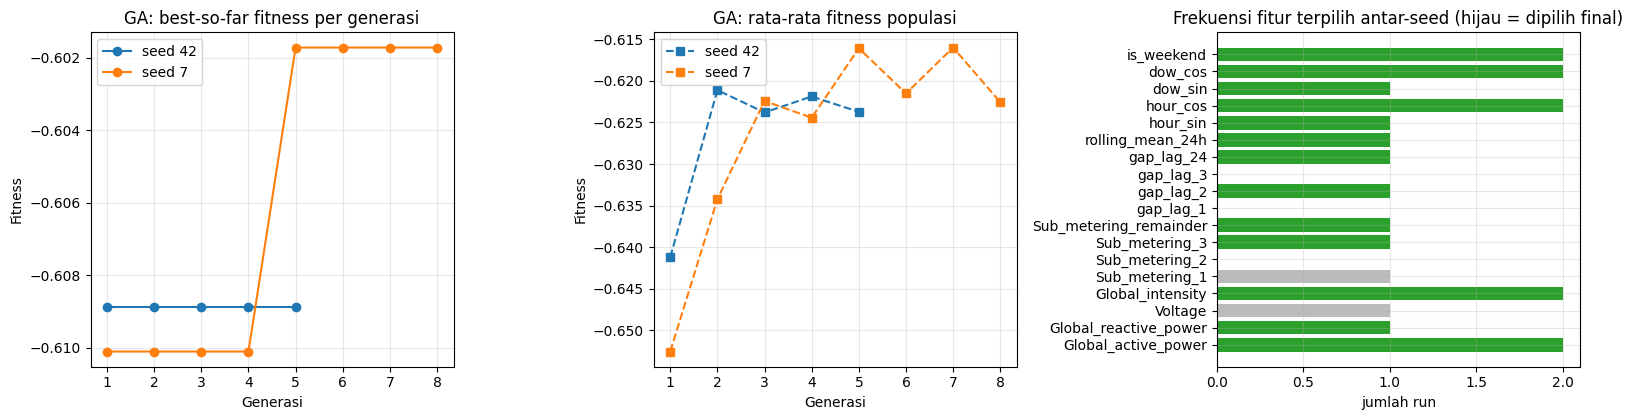

In [12]:
# SEL 12: LAPORAN GA - tabel run, fitur terpilih, frekuensi, dan kurva konvergensi
runs = ga_res['runs']
bi = int(np.argmax([r['best_fit'] for r in runs]))
GA_CHROM = np.array(runs[bi]['best_chrom'])
GA_IDX = [int(i) for i in np.flatnonzero(GA_CHROM)]
GA_FEATURES = [ALL_FEATURES[i] for i in GA_IDX]
GA_SEARCH_TIME = float(np.mean([r['time'] for r in runs]))

tab = pd.DataFrame([{'Seed': r['seed'], 'Best fitness': round(r['best_fit'], 4), 'RMSE val (kW)': round(r['best_rmse'], 4),
                     'Jumlah fitur': int(sum(r['best_chrom'])), 'Generasi dijalankan': r['gens_run'], 'Waktu (dtk)': round(r['time'])} for r in runs])
display(tab)
bf = [r['best_fit'] for r in runs]; br = [r['best_rmse'] for r in runs]
sd = (lambda v: float(np.std(v, ddof=1)) if len(v) > 1 else 0.0)
print(f'Fitness  best/mean/std : {max(bf):.4f} / {np.mean(bf):.4f} / {sd(bf):.4f}')
print(f'RMSE val best/mean/std : {min(br):.4f} / {np.mean(br):.4f} / {sd(br):.4f} kW')
print(f'Budget evaluasi: {sum(r["gens_run"] for r in runs) * cfg["ga_pop"]} panggilan fitness, {ga_res["n_unique_trainings"]} pelatihan proxy unik')
print(f'\n[Dipilih] Run seed {runs[bi]["seed"]} (fitness validasi terbaik): {len(GA_IDX)}/{N_ALL} fitur')

freq = np.sum([r['best_chrom'] for r in runs], axis=0)
ga_table = pd.DataFrame({'Fitur': ALL_FEATURES, 'Sebelum GA': '✓', 'Setelah GA': np.where(GA_CHROM == 1, '✓', '✗'),
                         f'Dipilih di {len(runs)} run': freq})
display(ga_table)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for r in runs:
    ax[0].plot(range(1, r['gens_run'] + 1), r['hist_best'], marker='o', label=f'seed {r["seed"]}')
    ax[1].plot(range(1, r['gens_run'] + 1), r['hist_mean'], marker='s', ls='--', label=f'seed {r["seed"]}')
ax[0].set_title('GA: best-so-far fitness per generasi'); ax[1].set_title('GA: rata-rata fitness populasi')
for a in ax[:2]:
    a.set_xlabel('Generasi'); a.set_ylabel('Fitness'); a.legend()
ax[2].barh(ALL_FEATURES, freq, color=['#2ca02c' if c else '#bbbbbb' for c in GA_CHROM])
ax[2].set_title('Frekuensi fitur terpilih antar-seed (hijau = dipilih final)'); ax[2].set_xlabel('jumlah run')
savefig('ga_convergence.png')

## Model B – GA + LSTM
Fitur hasil GA, hyperparameter **sama persis dengan baseline** (hanya fitur yang berbeda), sehingga dampak seleksi fitur terisolasi.

In [13]:
# SEL 13: MODEL B (GA + LSTM)
print(f'[TRAINING] Model B: {len(GA_IDX)} fitur hasil GA, hp baseline')
res_B = run_final('B', 'Model B - GA + LSTM', GA_IDX, BASE_HP, search_time=GA_SEARCH_TIME)

[TRAINING] Model B: 13 fitur hasil GA, hp baseline
  [B] seed 1: val RMSE 0.5201 | test RMSE 0.4662 kW | 30 epoch | 80 dtk
  [B] seed 2: val RMSE 0.5235 | test RMSE 0.4657 kW | 30 epoch | 78 dtk
[B] Model B - GA + LSTM: test RMSE 0.4659 ± 0.0004 | MAE 0.3208 | R² 0.5752 | 13 fitur | window 24h


## Particle Swarm Optimization – hyperparameter LSTM
**Particle (5 dimensi):** panjang window (12–36 jam, bulat), unit LSTM (16–64, kelipatan 8), dropout (0,05–0,35), log10 learning rate (−3,5 s.d. −2,3), indeks batch ∈ {32, 64, 128}.

**Objektif (diminimalkan):** RMSE validasi (kW) dari LSTM proxy. **Update:** `v ← w·v + c1·r1·(pbest−x) + c2·r2·(gbest−x)`, kecepatan di-clip `vmax = 0,25 × rentang`, posisi di-clip ke batas. Parameter: w=0,7; c1=c2=1,5. PSO dijalankan multi-seed.

PSO dijalankan **dua kali**: pada semua fitur (untuk Model C) dan pada fitur hasil GA (untuk Model D). Dengan begitu Model D benar-benar merupakan pipeline berurutan GA → PSO.

In [14]:
# SEL 14: IMPLEMENTASI PSO + FUNGSI DECODE
PSO_BMIN = np.array([SEQ_MIN, 16.0, 0.05, -3.5, 0.0])
PSO_BMAX = np.array([SEQ_MAX, 64.0, 0.35, -2.3, 2.99])
BATCH_CHOICES = [32, 64, 128]

def decode_particle(x):
    x = np.clip(x, PSO_BMIN, PSO_BMAX)
    units = int(np.clip(int(np.round(x[1] / 8.0)) * 8, 16, 64))
    return dict(seq_len=int(np.round(x[0])), units=units, dropout=float(round(x[2], 3)),
                lr=float(10 ** x[3]), batch=BATCH_CHOICES[int(min(np.floor(x[4]), 2))])

class PSOOptimizer:
    def __init__(self, bmin, bmax, decode, eval_fn, n_particles, iters, w, c1, c2, vmax_frac, seed):
        self.bmin, self.bmax, self.decode, self.eval_fn = bmin, bmax, decode, eval_fn
        self.n, self.iters, self.w, self.c1, self.c2 = n_particles, iters, w, c1, c2
        self.span = bmax - bmin; self.vmax = vmax_frac * self.span
        self.rng = np.random.RandomState(seed); self.dim = len(bmin)

    def run(self):
        pos = self.rng.uniform(self.bmin, self.bmax, (self.n, self.dim))
        vel = self.rng.uniform(-self.vmax, self.vmax, (self.n, self.dim))
        pbest, pbest_s = pos.copy(), np.full(self.n, np.inf)
        gbest, gbest_s = None, np.inf
        h_g, h_mean, history = [], [], []
        for it in range(self.iters):
            t0, sc = time.time(), []
            for i in range(self.n):
                hp = self.decode(pos[i]); s = self.eval_fn(hp); sc.append(s)
                history.append(dict(iter=it + 1, particle=i, rmse=float(s), **hp))
                if s < pbest_s[i]: pbest_s[i], pbest[i] = s, pos[i].copy()
                if s < gbest_s: gbest_s, gbest = float(s), pos[i].copy()
            h_g.append(gbest_s); h_mean.append(float(np.mean(sc)))
            b = self.decode(gbest)
            print(f'    Iter {it+1:02d}/{self.iters} | gbest RMSE {gbest_s:.4f} kW | window {b["seq_len"]}h, units {b["units"]}, lr {b["lr"]:.5f}, batch {b["batch"]} | rata-rata swarm {np.mean(sc):.4f} | {time.time()-t0:.0f} dtk')
            if it == self.iters - 1: break
            r1, r2 = self.rng.rand(self.n, self.dim), self.rng.rand(self.n, self.dim)
            vel = np.clip(self.w * vel + self.c1 * r1 * (pbest - pos) + self.c2 * r2 * (gbest - pos), -self.vmax, self.vmax)
            pos = np.clip(pos + vel, self.bmin, self.bmax)
        return dict(gbest_hp=self.decode(gbest), gbest_rmse=gbest_s, hist_gbest=h_g, hist_mean=h_mean, history=history)

def run_pso_stage(tag, feat_idx):
    def _do():
        cache, runs = {}, []
        def ev(hp):
            key = tuple(hp.values())
            if key not in cache:
                cache[key] = proxy_val_rmse(feat_idx, hp['seq_len'], hp['units'], hp['dropout'], hp['lr'], hp['batch'])
            return cache[key]
        for s in cfg['pso_seeds']:
            print(f'  --- PSO[{tag}] seed {s} ({cfg["pso_particles"]} partikel x {cfg["pso_iters"]} iterasi)')
            t0 = time.time()
            out = PSOOptimizer(PSO_BMIN, PSO_BMAX, decode_particle, ev, cfg['pso_particles'], cfg['pso_iters'],
                               cfg['pso_w'], cfg['pso_c1'], cfg['pso_c2'], cfg['pso_vmax'], s).run()
            out['seed'], out['time'] = s, time.time() - t0
            runs.append(out)
        return dict(runs=runs, n_unique_trainings=len(cache), n_features=len(feat_idx))
    return cached(f'pso_{tag}', _do)

def report_pso(tag, pso_res):
    runs = pso_res['runs']
    bi = int(np.argmin([r['gbest_rmse'] for r in runs]))
    display(pd.DataFrame([{'Seed': r['seed'], 'gbest RMSE val (kW)': round(r['gbest_rmse'], 4), 'Window': r['gbest_hp']['seq_len'],
                           'Units': r['gbest_hp']['units'], 'Dropout': r['gbest_hp']['dropout'], 'LR': round(r['gbest_hp']['lr'], 5),
                           'Batch': r['gbest_hp']['batch'], 'Waktu (dtk)': round(r['time'])} for r in runs]))
    g = [r['gbest_rmse'] for r in runs]
    print(f'gbest RMSE val best/mean/std: {min(g):.4f} / {np.mean(g):.4f} / {(np.std(g, ddof=1) if len(g) > 1 else 0.0):.4f} kW')
    print(f'Budget evaluasi: {len(runs) * cfg["pso_particles"] * cfg["pso_iters"]} panggilan, {pso_res["n_unique_trainings"]} pelatihan proxy unik')
    print(f'[Dipilih] seed {runs[bi]["seed"]}: {runs[bi]["gbest_hp"]}')
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for r in runs:
        ax[0].plot(range(1, len(r['hist_gbest']) + 1), r['hist_gbest'], marker='o', label=f'seed {r["seed"]}')
    ax[0].set_title(f'PSO[{tag}]: kurva gbest (RMSE val)'); ax[0].set_xlabel('Iterasi'); ax[0].set_ylabel('RMSE (kW)'); ax[0].legend()
    hist = pd.DataFrame([h for r in runs for h in r['history']])
    sc_ = ax[1].scatter(hist['units'], np.log10(hist['lr']), c=hist['rmse'], cmap='viridis_r', s=40)
    plt.colorbar(sc_, ax=ax[1], label='RMSE val (kW)'); ax[1].set_xlabel('LSTM units'); ax[1].set_ylabel('log10(learning rate)')
    ax[1].set_title(f'PSO[{tag}]: titik yang dievaluasi di search space')
    savefig(f'pso_{tag}.png')
    return runs[bi]['gbest_hp'], float(np.mean([r['time'] for r in runs]))
print('[OK] PSO siap.')

[OK] PSO siap.


[PSO-C] Optimasi hyperparameter pada SEMUA fitur ...
  --- PSO[C_semua_fitur] seed 42 (8 partikel x 6 iterasi)
    Iter 01/6 | gbest RMSE 0.5794 kW | window 21h, units 64, lr 0.00165, batch 32 | rata-rata swarm 0.6222 | 43 dtk
    Iter 02/6 | gbest RMSE 0.5794 kW | window 21h, units 64, lr 0.00165, batch 32 | rata-rata swarm 0.6138 | 52 dtk
    Iter 03/6 | gbest RMSE 0.5793 kW | window 24h, units 48, lr 0.00190, batch 32 | rata-rata swarm 0.5898 | 50 dtk
    Iter 04/6 | gbest RMSE 0.5729 kW | window 27h, units 56, lr 0.00265, batch 32 | rata-rata swarm 0.5808 | 50 dtk
    Iter 05/6 | gbest RMSE 0.5672 kW | window 25h, units 56, lr 0.00257, batch 32 | rata-rata swarm 0.5735 | 54 dtk
    Iter 06/6 | gbest RMSE 0.5627 kW | window 17h, units 56, lr 0.00373, batch 32 | rata-rata swarm 0.5780 | 53 dtk
  --- PSO[C_semua_fitur] seed 7 (8 partikel x 6 iterasi)
    Iter 01/6 | gbest RMSE 0.5745 kW | window 32h, units 56, lr 0.00154, batch 32 | rata-rata swarm 0.5995 | 46 dtk
    Iter 02/6 | gbes

,Seed,gbest RMSE val (kW),Window,Units,Dropout,LR,Batch,Waktu (dtk)
0,42,0.5627,17,56,0.161,0.00373,32,303
1,7,0.5644,35,56,0.193,0.00501,64,293


gbest RMSE val best/mean/std: 0.5627 / 0.5636 / 0.0012 kW
Budget evaluasi: 96 panggilan, 96 pelatihan proxy unik
[Dipilih] seed 42: {'seq_len': 17, 'units': 56, 'dropout': 0.161, 'lr': 0.0037269924853982725, 'batch': 32}


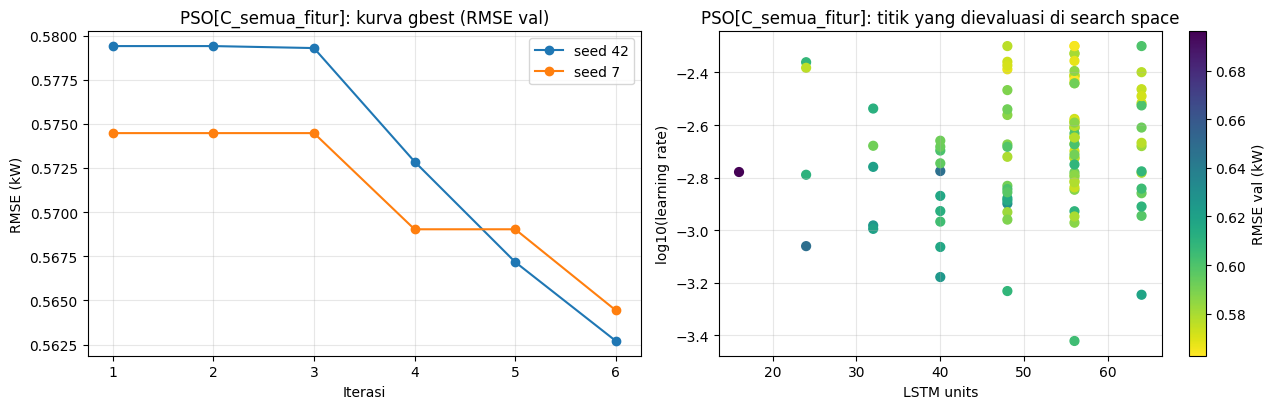


[TRAINING] Model C: 18 fitur + hyperparameter PSO
  [C] seed 1: val RMSE 0.5189 | test RMSE 0.4597 kW | 23 epoch | 118 dtk
  [C] seed 2: val RMSE 0.5203 | test RMSE 0.4693 kW | 17 epoch | 85 dtk
[C] Model C - PSO + LSTM: test RMSE 0.4645 ± 0.0068 | MAE 0.3204 | R² 0.5778 | 18 fitur | window 17h


In [15]:
# SEL 15: PSO UNTUK MODEL C (semua fitur) + MODEL C
print('[PSO-C] Optimasi hyperparameter pada SEMUA fitur ...')
pso_C = run_pso_stage('C_semua_fitur', ALL_IDX)
HP_C, PSO_C_TIME = report_pso('C_semua_fitur', pso_C)
print(f'\n[TRAINING] Model C: {N_ALL} fitur + hyperparameter PSO')
res_C = run_final('C', 'Model C - PSO + LSTM', ALL_IDX, HP_C, search_time=PSO_C_TIME)

[PSO-D] Optimasi hyperparameter pada 13 fitur hasil GA ...
  --- PSO[D_fitur_GA] seed 42 (8 partikel x 6 iterasi)
    Iter 01/6 | gbest RMSE 0.5862 kW | window 21h, units 64, lr 0.00165, batch 32 | rata-rata swarm 0.6182 | 46 dtk
    Iter 02/6 | gbest RMSE 0.5798 kW | window 18h, units 64, lr 0.00246, batch 32 | rata-rata swarm 0.5980 | 54 dtk
    Iter 03/6 | gbest RMSE 0.5691 kW | window 15h, units 48, lr 0.00193, batch 64 | rata-rata swarm 0.5799 | 56 dtk
    Iter 04/6 | gbest RMSE 0.5691 kW | window 15h, units 48, lr 0.00193, batch 64 | rata-rata swarm 0.5813 | 53 dtk
    Iter 05/6 | gbest RMSE 0.5691 kW | window 15h, units 48, lr 0.00193, batch 64 | rata-rata swarm 0.5743 | 50 dtk
    Iter 06/6 | gbest RMSE 0.5691 kW | window 15h, units 48, lr 0.00193, batch 64 | rata-rata swarm 0.5850 | 45 dtk
  --- PSO[D_fitur_GA] seed 7 (8 partikel x 6 iterasi)
    Iter 01/6 | gbest RMSE 0.5770 kW | window 34h, units 24, lr 0.00414, batch 32 | rata-rata swarm 0.6116 | 50 dtk
    Iter 02/6 | gbes

,Seed,gbest RMSE val (kW),Window,Units,Dropout,LR,Batch,Waktu (dtk)
0,42,0.5691,15,48,0.136,0.00193,64,304
1,7,0.5658,31,32,0.196,0.00360,32,347


gbest RMSE val best/mean/std: 0.5658 / 0.5675 / 0.0024 kW
Budget evaluasi: 96 panggilan, 96 pelatihan proxy unik
[Dipilih] seed 7: {'seq_len': 31, 'units': 32, 'dropout': 0.196, 'lr': 0.003601152909929756, 'batch': 32}


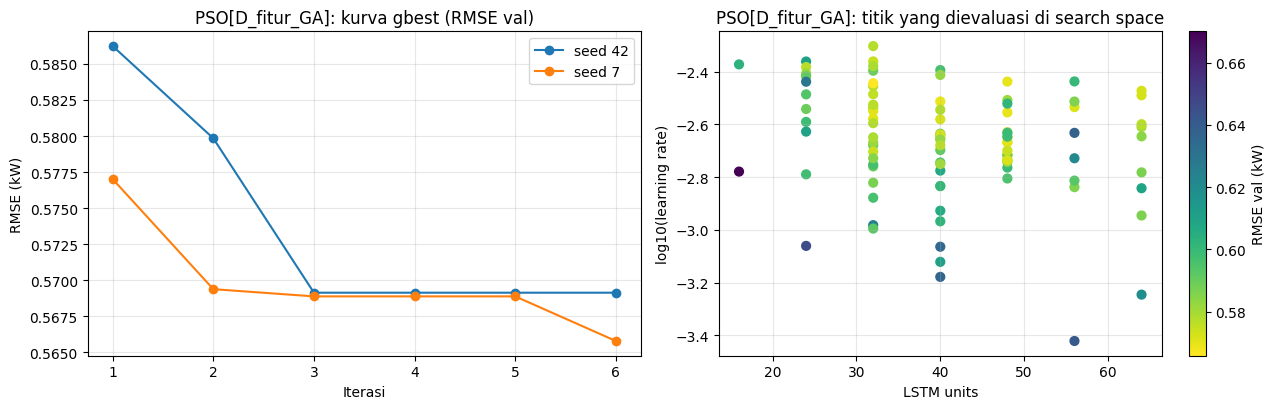


[TRAINING] Model D: 13 fitur GA + hyperparameter PSO
  [D] seed 1: val RMSE 0.5519 | test RMSE 0.4894 kW | 9 epoch | 47 dtk
  [D] seed 2: val RMSE 0.5207 | test RMSE 0.4631 kW | 30 epoch | 161 dtk
[D] Model D - GA + PSO + LSTM: test RMSE 0.4762 ± 0.0186 | MAE 0.3324 | R² 0.5559 | 13 fitur | window 31h


In [16]:
# SEL 16: PSO UNTUK MODEL D (fitur hasil GA) + MODEL D
print(f'[PSO-D] Optimasi hyperparameter pada {len(GA_IDX)} fitur hasil GA ...')
pso_D = run_pso_stage('D_fitur_GA', GA_IDX)
HP_D, PSO_D_TIME = report_pso('D_fitur_GA', pso_D)
print(f'\n[TRAINING] Model D: {len(GA_IDX)} fitur GA + hyperparameter PSO')
res_D = run_final('D', 'Model D - GA + PSO + LSTM', GA_IDX, HP_D, search_time=GA_SEARCH_TIME + PSO_D_TIME)

## Perbandingan empat konfigurasi (A, B, C, D)
Semua model memakai split yang sama, target test yang identik, dan di-training dengan beberapa seed. Tabel melaporkan **mean ± std** pada test set.

In [17]:
# SEL 17: TABEL PERBANDINGAN 4 MODEL + BASELINE NAIF
RES = {'A': res_A, 'B': res_B, 'C': res_C, 'D': res_D}
fm = lambda ms, d=4: f'{ms[0]:.{d}f} ± {ms[1]:.{d}f}'
comp = pd.DataFrame([{
    'Model': r['name'], 'Fitur': r['n_features'], 'Window (jam)': r['hp']['seq_len'], 'Units': r['hp']['units'],
    'Dropout': r['hp']['dropout'], 'LR': f"{r['hp']['lr']:.5f}", 'Batch': r['hp']['batch'], 'Parameter': r['n_params'],
    'MAE test (kW)': fm(r['test']['mae']), 'RMSE test (kW)': fm(r['test']['rmse']), 'R² test': fm(r['test']['r2']),
    'RMSE val (kW)': fm(r['val']['rmse']), 'Waktu train/run (dtk)': round(r['time_mean'], 1),
    'Waktu pencarian/run (dtk)': round(r['search_time'], 1)} for r in RES.values()])
display(comp)
print(f'Tiap model: {len(cfg["final_seeds"])} seed training | target test identik: {len(T_TEST):,} jam')
print('\nPembanding naif (tanpa model, test set yang sama):')
display(pd.DataFrame(naive_rows))

# Kesimpulan otomatis yang berhati-hati (tidak mengklaim perbaikan di dalam rentang noise antar-seed)
base_m, base_s = res_A['test']['rmse']
print('\n[ANALISIS RMSE TEST vs Baseline A]')
n_seed = len(cfg['final_seeds'])
for k in ('B', 'C', 'D'):
    m, s = RES[k]['test']['rmse']
    d = base_m - m
    noise = max(s, base_s)
    if n_seed < 2:
        verdict = 'TIDAK DAPAT DISIMPULKAN (hanya 1 seed, std tidak terdefinisi)'
    else:
        verdict = ('LEBIH BAIK (selisih > std antar-seed)' if d > noise else
                   'LEBIH BURUK (selisih > std antar-seed)' if -d > noise else 'TIDAK BEDA SIGNIFIKAN (selisih dalam rentang noise antar-seed)')
    print(f'  Model {k}: selisih RMSE = {d:+.4f} kW ({d/base_m*100:+.1f}%) -> {verdict}')
best_naive = min(v['rmse'] for v in NAIVE_TEST.values())
print(f'  Naif terbaik RMSE = {best_naive:.4f} kW; Model D = {res_D["test"]["rmse"][0]:.4f} kW')

,Model,Fitur,Window (jam),Units,Dropout,LR,Batch,Parameter,MAE test (kW),RMSE test (kW),R² test,RMSE val (kW),Waktu train/run (dtk),Waktu pencarian/run (dtk)
0,Model A - Baseline LSTM,18,24,32,0.100,0.00100,64,7073,0.3214 ± 0.0024,0.4684 ± 0.0027,0.5707 ± 0.0049,0.5233 ± 0.0054,71.3,0.0
1,Model B - GA + LSTM,13,24,32,0.100,0.00100,64,6433,0.3208 ± 0.0043,0.4659 ± 0.0004,0.5752 ± 0.0007,0.5218 ± 0.0024,79.1,199.8
2,Model C - PSO + LSTM,18,17,56,0.161,0.00373,32,17729,0.3204 ± 0.0077,0.4645 ± 0.0068,0.5778 ± 0.0123,0.5196 ± 0.0010,101.5,297.6
3,Model D - GA + PSO + LSTM,13,31,32,0.196,0.00360,32,6433,0.3324 ± 0.0026,0.4762 ± 0.0186,0.5559 ± 0.0346,0.5363 ± 0.0221,104.0,525.0


Tiap model: 2 seed training | target test identik: 4,858 jam

Pembanding naif (tanpa model, test set yang sama):


,Metode,MAE (kW),RMSE (kW),R²
0,Naif: sama dengan jam sebelumnya,0.3904,0.5900,0.3190
1,Naif: sama dengan 24 jam lalu,0.5158,0.7666,-0.1498
2,Naif: rata-rata 24 jam terakhir,0.5376,0.6846,0.0831



[ANALISIS RMSE TEST vs Baseline A]
  Model B: selisih RMSE = +0.0025 kW (+0.5%) -> TIDAK BEDA SIGNIFIKAN (selisih dalam rentang noise antar-seed)
  Model C: selisih RMSE = +0.0039 kW (+0.8%) -> TIDAK BEDA SIGNIFIKAN (selisih dalam rentang noise antar-seed)
  Model D: selisih RMSE = -0.0078 kW (-1.7%) -> TIDAK BEDA SIGNIFIKAN (selisih dalam rentang noise antar-seed)
  Naif terbaik RMSE = 0.5900 kW; Model D = 0.4762 kW


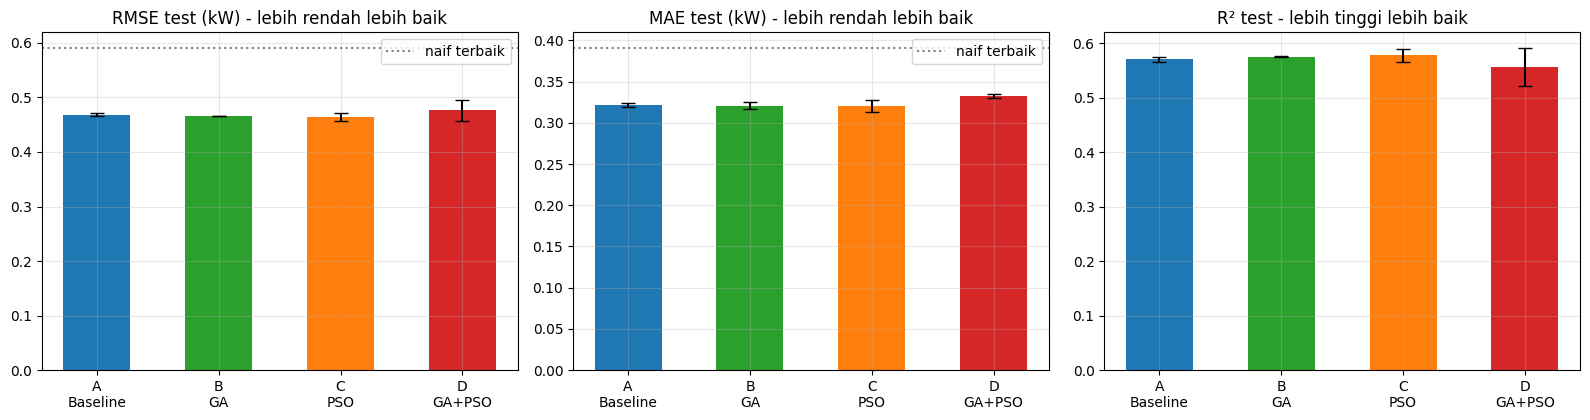

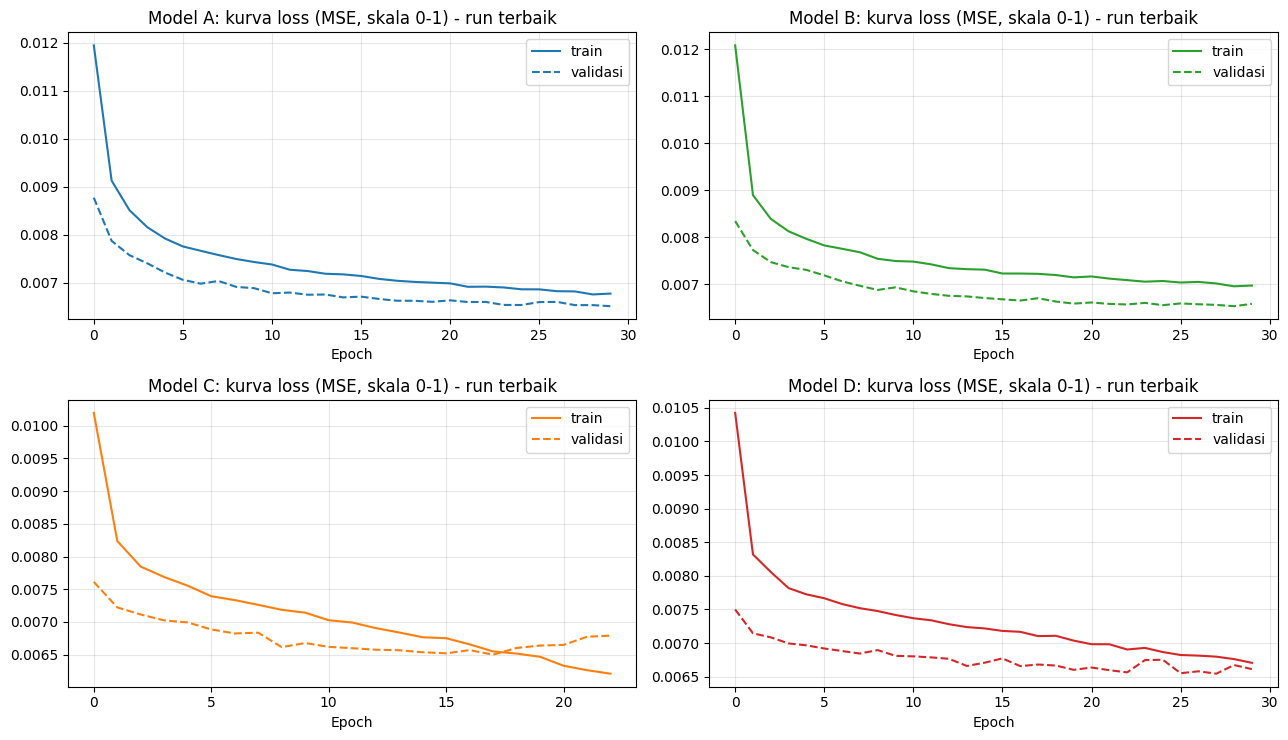

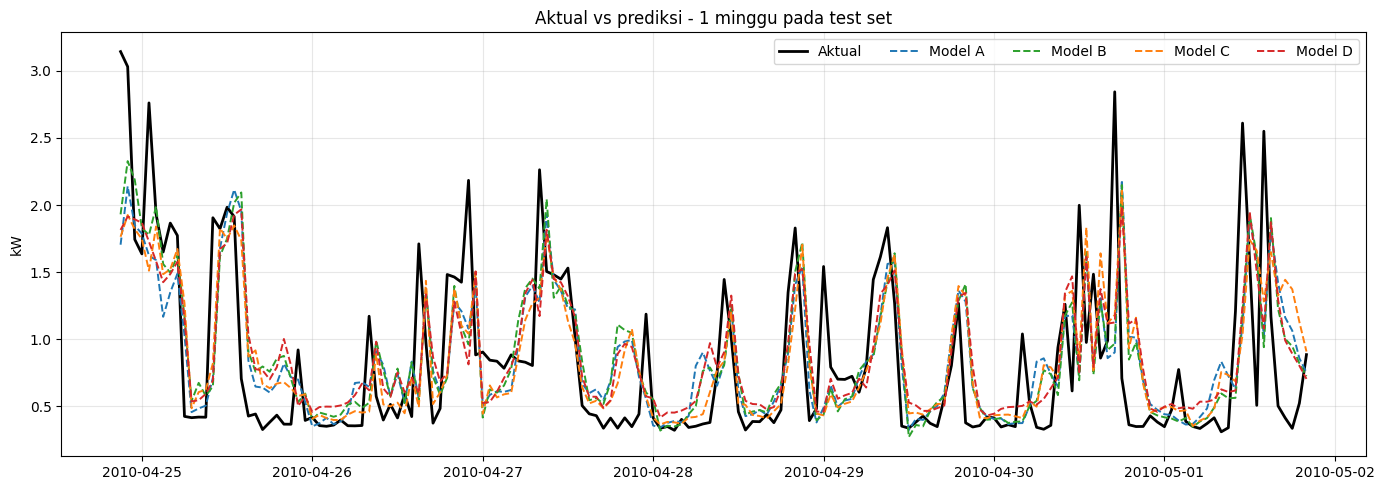

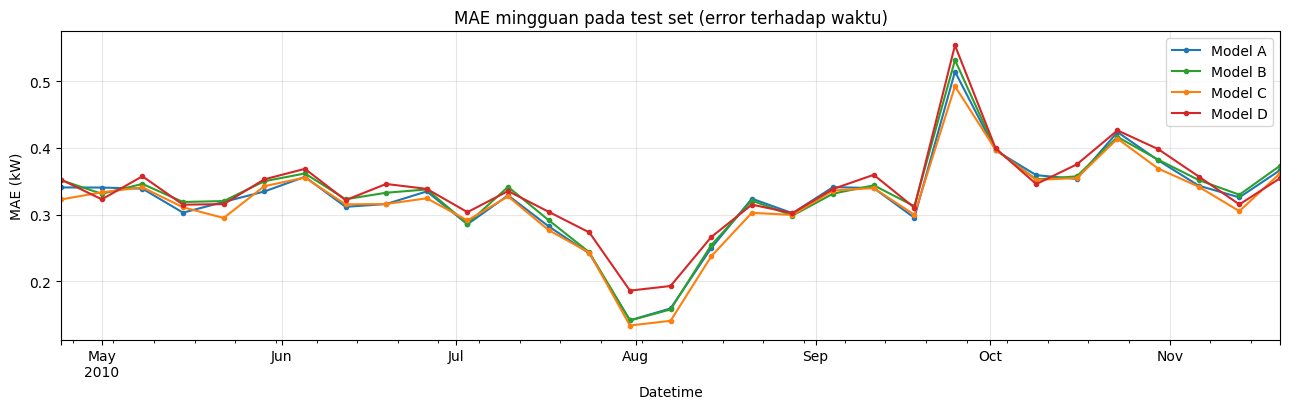

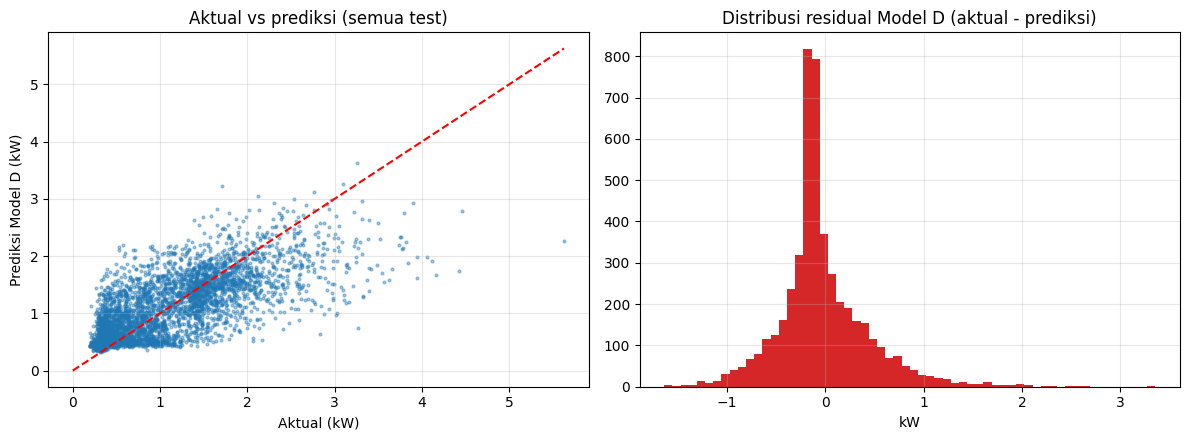

In [18]:
# SEL 18: GRAFIK PERBANDINGAN - bar, kurva training, actual vs predicted, error terhadap waktu
labels = ['A\nBaseline', 'B\nGA', 'C\nPSO', 'D\nGA+PSO']
cols = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for i, key in enumerate(('rmse', 'mae', 'r2')):
    m = [RES[k]['test'][key][0] for k in 'ABCD']; s = [RES[k]['test'][key][1] for k in 'ABCD']
    ax[i].bar(labels, m, yerr=s, capsize=5, color=cols, width=0.55)
    ax[i].set_title({'rmse': 'RMSE test (kW) - lebih rendah lebih baik', 'mae': 'MAE test (kW) - lebih rendah lebih baik', 'r2': 'R² test - lebih tinggi lebih baik'}[key])
    if key != 'r2': ax[i].axhline(best_naive if key == 'rmse' else min(v['mae'] for v in NAIVE_TEST.values()), color='gray', ls=':', label='naif terbaik'); ax[i].legend()
savefig('compare_metrics.png')

fig, ax = plt.subplots(2, 2, figsize=(13, 7.5), sharey=False)
for a, k, c in zip(ax.ravel(), 'ABCD', cols):
    h = RES[k]['runs'][RES[k]['best_run']]['history']
    a.plot(h['loss'], color=c, label='train'); a.plot(h['val_loss'], color=c, ls='--', label='validasi')
    a.set_title(f'Model {k}: kurva loss (MSE, skala 0-1) - run terbaik'); a.set_xlabel('Epoch'); a.legend()
savefig('compare_training_curves.png')

def contiguous_segment(t_idx, length):
    brk = np.flatnonzero(np.diff(t_idx) != 1) + 1
    st, en = np.r_[0, brk], np.r_[brk, len(t_idx)]
    for s, e in zip(st, en):
        if e - s >= length: return slice(s, s + length)
    s, e = max(zip(st, en), key=lambda se: se[1] - se[0])
    return slice(s, min(e, s + length))

seg = contiguous_segment(T_TEST, 168)
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(TS_TEST[seg], y_test_kw[seg], color='black', lw=2, label='Aktual')
for k, c in zip('ABCD', cols):
    ax.plot(TS_TEST[seg], RES[k]['runs'][RES[k]['best_run']]['pred_test'][seg], color=c, lw=1.4, ls='--', label=f'Model {k}')
ax.set_title('Aktual vs prediksi - 1 minggu pada test set'); ax.set_ylabel('kW'); ax.legend(ncol=5)
savefig('compare_actual_vs_pred_week.png')

# Error terhadap waktu (rata-rata mingguan) - wajib untuk time series
fig, ax = plt.subplots(figsize=(13, 4.2))
for k, c in zip('ABCD', cols):
    e = np.abs(y_test_kw - RES[k]['runs'][RES[k]['best_run']]['pred_test'])
    pd.Series(e, index=TS_TEST).resample('7D').mean().plot(ax=ax, color=c, marker='o', ms=3, label=f'Model {k}')
ax.set_title('MAE mingguan pada test set (error terhadap waktu)'); ax.set_ylabel('MAE (kW)'); ax.legend()
savefig('compare_error_over_time.png')

pD = RES['D']['runs'][RES['D']['best_run']]['pred_test']
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test_kw, pD, s=4, alpha=0.4); lim = [0, max(y_test_kw.max(), pD.max())]
ax[0].plot(lim, lim, 'r--'); ax[0].set_xlabel('Aktual (kW)'); ax[0].set_ylabel('Prediksi Model D (kW)'); ax[0].set_title('Aktual vs prediksi (semua test)')
ax[1].hist(y_test_kw - pD, bins=60, color='#d62728'); ax[1].set_title('Distribusi residual Model D (aktual - prediksi)'); ax[1].set_xlabel('kW')
savefig('model_D_scatter_residual.png')

## Fuzzy Inference System (Mamdani) – Model E
**Input 1:** prediksi beban jam berikutnya `P` (kW). **Input 2:** perubahan `ΔP = prediksi − beban aktual jam terakhir` (kW). **Output:** indeks status beban 0–100 → label *Very Low / Low / Normal / High / Peak*.

**Membership function** untuk `P` dan `ΔP` diturunkan dari **persentil data latih** (partisi Ruspini, jadi tidak ada celah). Output memakai 5 himpunan merata. **Rule base:** 5×3 = 15 aturan IF–THEN. **Inferensi:** implikasi min, agregasi max, defuzzifikasi *centroid*. Label akhir = himpunan output dengan keanggotaan tertinggi pada nilai centroid.

Catatan: fuzzy adalah **lapisan keputusan**, bukan peningkat akurasi prediksi. Fuzzy dievaluasi lewat konsistensi aturan, skenario ekstrem, dan kesesuaian keputusan, bukan lewat RMSE.

In [19]:
# SEL 19: IMPLEMENTASI FIS MAMDANI
STATUS = ['Very Low', 'Low', 'Normal', 'High', 'Peak']
DELTA = ['Decreasing', 'Steady', 'Increasing']
RULES = {('Very Low','Decreasing'):'Very Low', ('Very Low','Steady'):'Very Low', ('Very Low','Increasing'):'Low',
         ('Low','Decreasing'):'Very Low',       ('Low','Steady'):'Low',        ('Low','Increasing'):'Normal',
         ('Normal','Decreasing'):'Low',         ('Normal','Steady'):'Normal',  ('Normal','Increasing'):'High',
         ('High','Decreasing'):'Normal',        ('High','Steady'):'High',      ('High','Increasing'):'Peak',
         ('Peak','Decreasing'):'High',          ('Peak','Steady'):'Peak',      ('Peak','Increasing'):'Peak'}
STATUS_COLOR = {'Very Low': '#2ca02c', 'Low': '#1f77b4', 'Normal': '#ff7f0e', 'High': '#d62728', 'Peak': '#7f1416'}
RECOMMEND = {'Very Low': 'Beban sangat rendah (rumah kosong/malam). Tidak perlu tindakan.',
             'Low': 'Beban dasar (perangkat standby/kulkas). Kondisi aman.',
             'Normal': 'Aktivitas rumah tangga normal. Pantau saja.',
             'High': 'Pemakaian intensif. Pertimbangkan menggeser alat berdaya besar.',
             'Peak': 'Beban puncak. Tunda pemakaian alat berdaya besar bila memungkinkan.'}

def trimf(x, a, b, c):
    x = np.asarray(x, float); y = np.zeros_like(x)
    if b > a: m = (x >= a) & (x <= b); y[m] = (x[m] - a) / (b - a)
    if c > b: m = (x > b) & (x <= c); y[m] = (c - x[m]) / (c - b)
    y[x == b] = 1.0
    return y

def trapmf(x, a, b, c, d):
    x = np.asarray(x, float); y = np.zeros_like(x)
    if b > a: m = (x >= a) & (x < b); y[m] = (x[m] - a) / (b - a)
    m = (x >= b) & (x <= c); y[m] = 1.0
    if d > c: m = (x > c) & (x <= d); y[m] = (d - x[m]) / (d - c)
    return y

def mf_eval(spec, x):
    return trimf(x, *spec[1:]) if spec[0] == 'tri' else trapmf(x, *spec[1:])

def make_fuzzy_params(train_p, train_dp, umax=7.0):
    c = np.quantile(train_p, [0.10, 0.35, 0.60, 0.85, 0.95]).astype(float)
    c = c + np.arange(5) * 1e-6
    dl = max(float(np.quantile(np.abs(train_dp), 0.70)), 0.05)
    dmax = float(max(2.0, np.ceil(np.abs(train_dp).max())))
    return dict(
        umax=float(umax), dmax=dmax,
        p_mf={'Very Low': ['trap', 0, 0, c[0], c[1]], 'Low': ['tri', c[0], c[1], c[2]], 'Normal': ['tri', c[1], c[2], c[3]],
              'High': ['tri', c[2], c[3], c[4]], 'Peak': ['trap', c[3], c[4], umax, umax]},
        d_mf={'Decreasing': ['trap', -dmax, -dmax, -dl, 0.0], 'Steady': ['tri', -dl, 0.0, dl], 'Increasing': ['trap', 0.0, dl, dmax, dmax]},
        out_mf={'Very Low': ['trap', 0, 0, 10, 30], 'Low': ['tri', 10, 30, 50], 'Normal': ['tri', 30, 50, 70],
                'High': ['tri', 50, 70, 90], 'Peak': ['trap', 70, 90, 100, 100]},
        rules=[[p, d, o] for (p, d), o in RULES.items()], quantiles_P=[float(v) for v in c], delta_scale=float(dl))

class MamdaniFIS:
    def __init__(self, params):
        self.p = params
        self.out_u = np.linspace(0, 100, 1001)
        self.mu_out = {k: mf_eval(v, self.out_u) for k, v in params['out_mf'].items()}

    def _fuzzify(self, P, D):
        P = np.clip(np.asarray(P, float), 0, self.p['umax']); D = np.clip(np.asarray(D, float), -self.p['dmax'], self.p['dmax'])
        return ({k: mf_eval(v, P) for k, v in self.p['p_mf'].items()}, {k: mf_eval(v, D) for k, v in self.p['d_mf'].items()})

    def infer(self, P, D, chunk=2000):
        P, D = np.atleast_1d(np.asarray(P, float)), np.atleast_1d(np.asarray(D, float))
        scores = np.zeros(len(P))
        for s in range(0, len(P), chunk):
            mp, md_ = self._fuzzify(P[s:s+chunk], D[s:s+chunk])
            agg = np.zeros((len(mp['Normal']), len(self.out_u)))
            for (pc, dc), oc in RULES.items():
                w = np.minimum(mp[pc], md_[dc])
                agg = np.maximum(agg, np.minimum(w[:, None], self.mu_out[oc][None, :]))
            den = agg.sum(axis=1)
            scores[s:s+chunk] = np.where(den > 0, (agg * self.out_u).sum(axis=1) / np.where(den > 0, den, 1), 50.0)
        mu_at = np.stack([mf_eval(self.p['out_mf'][k], scores) for k in STATUS], axis=1)
        return scores, np.argmax(mu_at, axis=1)

    def evaluate(self, p, d):
        sc, si = self.infer([p], [d]); mp, md_ = self._fuzzify([p], [d])
        fired = sorted([dict(rule=f'IF P is {pc} AND dP is {dc} THEN Status is {oc}', weight=round(float(min(mp[pc][0], md_[dc][0])), 4))
                        for (pc, dc), oc in RULES.items() if min(mp[pc][0], md_[dc][0]) > 0], key=lambda r: -r['weight'])
        st = STATUS[int(si[0])]
        return dict(power_kw=float(p), delta_kw=float(d), fuzzy_score=round(float(sc[0]), 2), status=st,
                    color=STATUS_COLOR[st], recommendation=RECOMMEND[st], active_rules=fired)

tr_rows = fit_rows
train_dp = (y_kw_all[1:tr_end] - y_kw_all[:tr_end-1])[(ok_arr[1:tr_end] & ok_arr[:tr_end-1])]
FUZZY_PARAMS = make_fuzzy_params(y_kw_all[tr_rows], train_dp)
fis = MamdaniFIS(FUZZY_PARAMS)
print('[OK] FIS siap. Pusat himpunan P (persentil train 10/35/60/85/95, kW):', [round(v, 3) for v in FUZZY_PARAMS['quantiles_P']])
print(f'     Skala delta (persentil-70 |dP| train): {FUZZY_PARAMS["delta_scale"]:.3f} kW | 15 aturan')

[OK] FIS siap. Pusat himpunan P (persentil train 10/35/60/85/95, kW): [0.261, 0.402, 1.139, 2.03, 2.942]
     Skala delta (persentil-70 |dP| train): 0.585 kW | 15 aturan


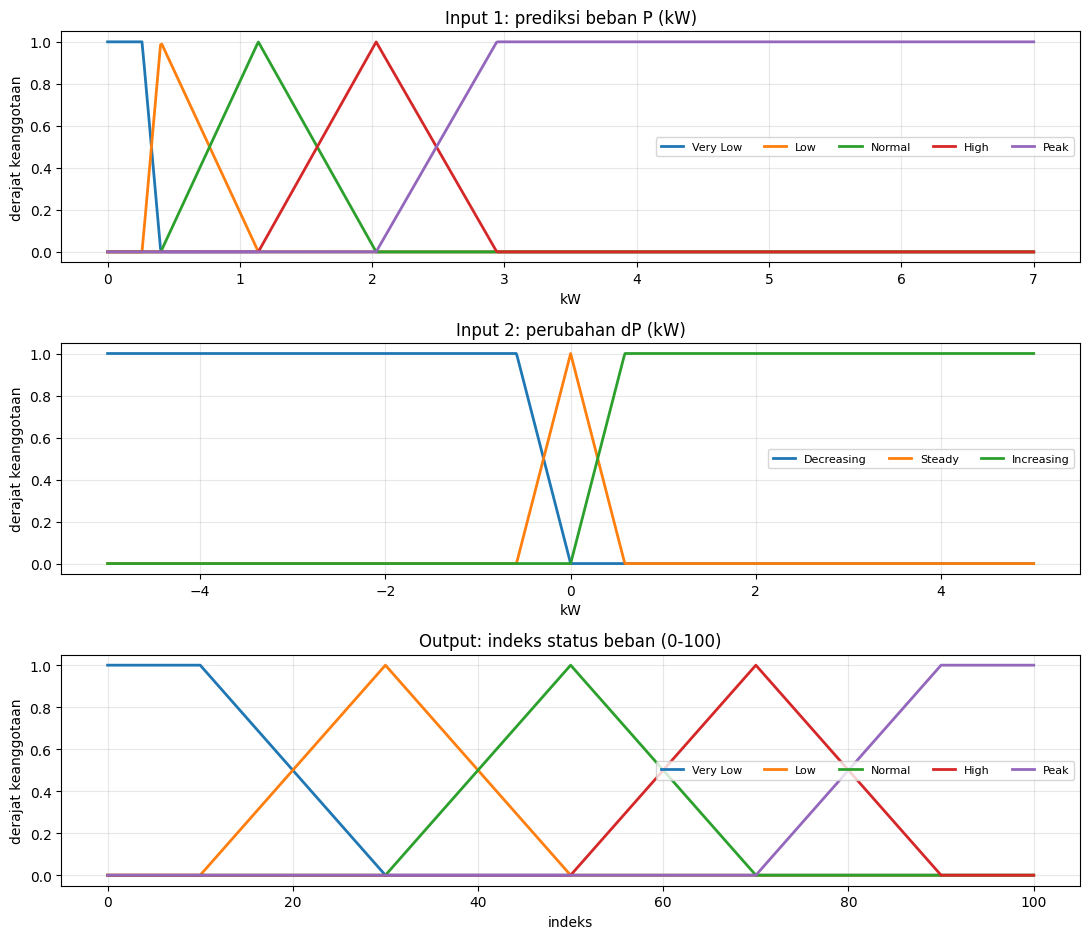

RULE TABLE (baris = P, kolom = dP, isi = status output):


,Decreasing,Steady,Increasing
P \ dP,,,
Very Low,Very Low,Very Low,Low
Low,Very Low,Low,Normal
Normal,Low,Normal,High
High,Normal,High,Peak
Peak,High,Peak,Peak



[KONSISTENSI] thd P : riak kecil 40 langkah (terburuk -1.25 poin) | pelanggaran nyata (> 2.0 poin): 0
[KONSISTENSI] thd dP: riak kecil 20 langkah (terburuk -0.83 poin) | pelanggaran nyata (> 2.0 poin): 0


,Skenario,P (kW),dP (kW),Skor,Status,Aturan aktif
0,"Ekstrem: beban 0 kW, turun drastis",0.00,-5.00,10.81,Very Low,1
1,"Ekstrem: beban 0 kW, naik drastis",0.00,5.00,30.00,Low,1
2,"Ekstrem: beban 7 kW, naik drastis",7.00,5.00,89.19,Peak,1
3,"Ekstrem: beban 7 kW, turun drastis",7.00,-5.00,70.00,High,1
4,Malam / rumah kosong,0.25,-0.05,11.07,Very Low,2
5,Pagi / standby,0.60,0.05,39.00,Low,4
6,Siang normal,1.30,0.10,57.63,Normal,4
7,Sore memasak (lonjakan),2.80,0.90,88.70,Peak,2
8,Puncak malam,4.50,0.30,87.41,Peak,2
9,Pasca puncak (ramp down),3.20,-1.20,70.00,High,1


Contoh penjelasan keputusan (P=2.8 kW, dP=+0.9 kW) -> Peak | skor 88.7
   0.8444 IF P is Peak AND dP is Increasing THEN Status is Peak
   0.1556 IF P is High AND dP is Increasing THEN Status is Peak


In [20]:
# SEL 20: MEMBERSHIP FUNCTION, RULE TABLE, UJI KONSISTENSI, DAN SKENARIO EKSTREM
fig, ax = plt.subplots(3, 1, figsize=(11, 9.5))
xs = {'p_mf': np.linspace(0, FUZZY_PARAMS['umax'], 701), 'd_mf': np.linspace(-FUZZY_PARAMS['dmax'], FUZZY_PARAMS['dmax'], 801), 'out_mf': fis.out_u}
for a, key, ttl, xl in zip(ax, ('p_mf', 'd_mf', 'out_mf'), ('Input 1: prediksi beban P (kW)', 'Input 2: perubahan dP (kW)', 'Output: indeks status beban (0-100)'), ('kW', 'kW', 'indeks')):
    for k, spec in FUZZY_PARAMS[key].items():
        a.plot(xs[key], mf_eval(spec, xs[key]), lw=2, label=k)
    a.set_title(ttl); a.set_xlabel(xl); a.set_ylabel('derajat keanggotaan'); a.legend(ncol=5, fontsize=8)
savefig('fuzzy_membership.png')

print('RULE TABLE (baris = P, kolom = dP, isi = status output):')
display(pd.DataFrame([[RULES[(p, d)] for d in DELTA] for p in STATUS], index=pd.Index(STATUS, name='P \\ dP'), columns=DELTA))

# Uji konsistensi: skor tidak boleh turun ketika P naik (dP tetap) atau dP naik (P tetap).
# Defuzzifikasi centroid wajar menghasilkan riak kecil; yang dianggap pelanggaran nyata adalah penurunan > TOL poin (skala 0-100).
TOL = 2.0
def _mono(xs_fixed, vary, mk):
    strict, real, worst = 0, 0, 0.0
    for fx in xs_fixed:
        P_, D_ = mk(fx)
        s_, _ = fis.infer(P_, D_); dd = np.diff(s_)
        strict += int((dd < -1e-6).sum()); real += int((dd < -TOL).sum()); worst = min(worst, float(dd.min()))
    return strict, real, worst
P_grid = np.linspace(0, FUZZY_PARAMS['umax'], 141); D_grid = np.linspace(-FUZZY_PARAMS['dmax'], FUZZY_PARAMS['dmax'], 81)
sP, rP, wP = _mono(np.linspace(-FUZZY_PARAMS['dmax'], FUZZY_PARAMS['dmax'], 9), 'P', lambda d: (P_grid, np.full_like(P_grid, d)))
sD, rD, wD = _mono(np.linspace(0, FUZZY_PARAMS['umax'], 15), 'D', lambda p: (np.full_like(D_grid, p), D_grid))
print(f'\n[KONSISTENSI] thd P : riak kecil {sP} langkah (terburuk {wP:.2f} poin) | pelanggaran nyata (> {TOL} poin): {rP}')
print(f'[KONSISTENSI] thd dP: riak kecil {sD} langkah (terburuk {wD:.2f} poin) | pelanggaran nyata (> {TOL} poin): {rD}')
CONSISTENCY = dict(tolerance=TOL, ripples_P=sP, real_violations_P=rP, worst_drop_P=wP, ripples_dP=sD, real_violations_dP=rD, worst_drop_dP=wD)

u, dm = FUZZY_PARAMS['umax'], FUZZY_PARAMS['dmax']
scen = [('Ekstrem: beban 0 kW, turun drastis', 0.0, -dm), ('Ekstrem: beban 0 kW, naik drastis', 0.0, dm),
        (f'Ekstrem: beban {u:.0f} kW, naik drastis', u, dm), (f'Ekstrem: beban {u:.0f} kW, turun drastis', u, -dm),
        ('Malam / rumah kosong', 0.25, -0.05), ('Pagi / standby', 0.60, 0.05), ('Siang normal', 1.30, 0.10),
        ('Sore memasak (lonjakan)', 2.80, 0.90), ('Puncak malam', 4.50, 0.30), ('Pasca puncak (ramp down)', 3.20, -1.20)]
srows = []
for nm, p, d in scen:
    r = fis.evaluate(p, d); srows.append({'Skenario': nm, 'P (kW)': round(p, 2), 'dP (kW)': round(d, 2), 'Skor': r['fuzzy_score'], 'Status': r['status'], 'Aturan aktif': len(r['active_rules'])})
display(pd.DataFrame(srows))
ex = fis.evaluate(2.8, 0.9)
print('Contoh penjelasan keputusan (P=2.8 kW, dP=+0.9 kW) ->', ex['status'], '| skor', ex['fuzzy_score'])
for r in ex['active_rules']: print('  ', r['weight'], r['rule'])

KESESUAIAN KEPUTUSAN FUZZY TERHADAP KEPUTUSAN DARI BEBAN AKTUAL (test set):
  Model E (prediksi Model D -> fuzzy): persis sama 37.6% | selisih <=1 tingkat 85.7%
  Pembanding naif (jam lalu -> fuzzy) : persis sama 34.7% | selisih <=1 tingkat 72.5%


Prediksi,Very Low,Low,Normal,High,Peak
Aktual,,,,,
Very Low,41,559,249,26,1
Low,6,876,760,129,8
Normal,2,231,602,181,17
High,0,110,396,243,26
Peak,0,19,135,175,66


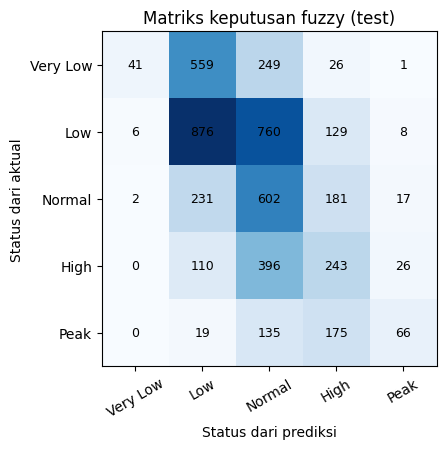

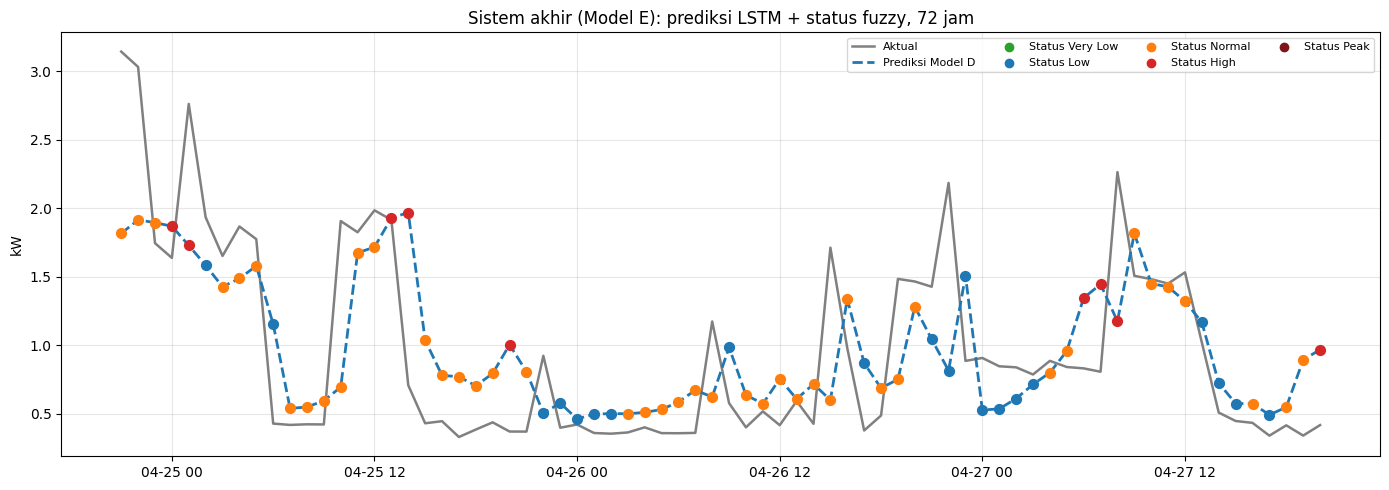

,Konfigurasi,Fitur,RMSE test (kW),MAE test (kW),R² test,Keputusan fuzzy,Kesesuaian keputusan (%)
0,Model A - Baseline LSTM,18,0.4684 ± 0.0027,0.3214 ± 0.0024,0.5707 ± 0.0049,-,-
1,Model B - GA + LSTM,13,0.4659 ± 0.0004,0.3208 ± 0.0043,0.5752 ± 0.0007,-,-
2,Model C - PSO + LSTM,18,0.4645 ± 0.0068,0.3204 ± 0.0077,0.5778 ± 0.0123,-,-
3,Model D - GA + PSO + LSTM,13,0.4762 ± 0.0186,0.3324 ± 0.0026,0.5559 ± 0.0346,-,-
4,Model E - D + Fuzzy,13,0.4762 ± 0.0186,0.3324 ± 0.0026,0.5559 ± 0.0346,5 status,37.6 (±1 tingkat: 85.7)


Catatan: Fuzzy tidak mengubah prediksi, jadi metrik regresi Model E = Model D. Nilai tambah fuzzy diukur pada keputusan, bukan akurasi.


In [21]:
# SEL 21: MODEL E = D + FUZZY. Evaluasi keputusan pada test set (kesesuaian keputusan, BUKAN akurasi NN)
prev_actual = y_kw_all[T_TEST - 1]
pred_D = RES['D']['runs'][RES['D']['best_run']]['pred_test']

sc_act, st_act = fis.infer(y_test_kw, y_test_kw - prev_actual)          # keputusan "acuan" dari beban aktual
sc_D, st_D = fis.infer(pred_D, pred_D - prev_actual)                    # keputusan dari prediksi Model D
sc_nv, st_nv = fis.infer(prev_actual, np.zeros_like(prev_actual))       # keputusan dari persistence (tanpa model)

def agree(a, b): return float((a == b).mean() * 100), float((np.abs(a - b) <= 1).mean() * 100)
ag_D, ag_nv = agree(st_act, st_D), agree(st_act, st_nv)
print('KESESUAIAN KEPUTUSAN FUZZY TERHADAP KEPUTUSAN DARI BEBAN AKTUAL (test set):')
print(f'  Model E (prediksi Model D -> fuzzy): persis sama {ag_D[0]:.1f}% | selisih <=1 tingkat {ag_D[1]:.1f}%')
print(f'  Pembanding naif (jam lalu -> fuzzy) : persis sama {ag_nv[0]:.1f}% | selisih <=1 tingkat {ag_nv[1]:.1f}%')
cm = pd.crosstab(pd.Categorical([STATUS[i] for i in st_act], STATUS), pd.Categorical([STATUS[i] for i in st_D], STATUS), rownames=['Aktual'], colnames=['Prediksi'], dropna=False)
display(cm)
fig, ax = plt.subplots(figsize=(5.5, 4.6)); ax.grid(False)
im = ax.imshow(cm.values, cmap='Blues'); ax.set_xticks(range(5)); ax.set_xticklabels(STATUS, rotation=30); ax.set_yticks(range(5)); ax.set_yticklabels(STATUS)
for i in range(5):
    for j in range(5): ax.text(j, i, int(cm.values[i, j]), ha='center', va='center', fontsize=9)
ax.set_xlabel('Status dari prediksi'); ax.set_ylabel('Status dari aktual'); ax.set_title('Matriks keputusan fuzzy (test)')
savefig('fuzzy_decision_confusion.png')

seg = contiguous_segment(T_TEST, 72)
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(TS_TEST[seg], y_test_kw[seg], color='gray', lw=1.8, label='Aktual')
ax.plot(TS_TEST[seg], pred_D[seg], color='#1f77b4', ls='--', lw=2, label='Prediksi Model D')
for i, k in enumerate(np.arange(len(T_TEST))[seg]):
    ax.scatter(TS_TEST[k], pred_D[k], color=STATUS_COLOR[STATUS[st_D[k]]], s=50, zorder=5)
for s in STATUS: ax.scatter([], [], color=STATUS_COLOR[s], label=f'Status {s}')
ax.set_title('Sistem akhir (Model E): prediksi LSTM + status fuzzy, 72 jam'); ax.set_ylabel('kW'); ax.legend(ncol=4, fontsize=8)
savefig('model_E_timeline.png')

ablation = pd.DataFrame([{'Konfigurasi': r['name'], 'Fitur': r['n_features'], 'RMSE test (kW)': fm(r['test']['rmse']), 'MAE test (kW)': fm(r['test']['mae']),
                          'R² test': fm(r['test']['r2']), 'Keputusan fuzzy': '-', 'Kesesuaian keputusan (%)': '-'} for r in RES.values()])
ablation.loc[len(ablation)] = ['Model E - D + Fuzzy', res_D['n_features'], fm(res_D['test']['rmse']), fm(res_D['test']['mae']), fm(res_D['test']['r2']),
                               '5 status', f'{ag_D[0]:.1f} (±1 tingkat: {ag_D[1]:.1f})']
display(ablation)
print('Catatan: Fuzzy tidak mengubah prediksi, jadi metrik regresi Model E = Model D. Nilai tambah fuzzy diukur pada keputusan, bukan akurasi.')

## Pipeline inference end-to-end dan ekspor artefak
`predict_and_decide()` menjalankan alur yang akan dipakai dashboard Streamlit: **data per jam → fitur → scaler → LSTM (Model D) → fuzzy → keputusan**. Uji konsistensi memastikan hasilnya sama dengan prediksi saat evaluasi.

In [22]:
# SEL 22: PIPELINE INFERENCE END-TO-END + UJI KONSISTENSI DENGAN HASIL EVALUASI
model_D = keras.models.load_model(MODELS_DIR / 'model_D.keras')      # memuat ulang model dari disk (bukti artefak dapat dimuat)
SEQ_D, IDX_D = res_D['hp']['seq_len'], res_D['feat_idx']

def predict_and_decide(base_hourly, model=model_D, feat_idx=IDX_D, seq_len=SEQ_D):
    # base_hourly: DataFrame per jam (index datetime) dengan 7 kolom UCI asli, minimal seq_len+25 jam terakhir.
    if len(base_hourly) < seq_len + 25:
        raise ValueError(f'Butuh minimal {seq_len + 25} jam data historis, diberikan {len(base_hourly)}.')
    feats = build_features(base_hourly).dropna()
    Xs = feat_scaler.transform(feats[ALL_FEATURES])[-seq_len:][:, feat_idx].astype(np.float32)
    pred = float(inv_target(model.predict(Xs[None], verbose=0))[0])
    last_actual = float(base_hourly[TARGET].iloc[-1])
    out = fis.evaluate(pred, pred - last_actual)
    out.update(predicted_kw=pred, last_actual_kw=last_actual, forecast_for=str(base_hourly.index[-1] + pd.Timedelta(hours=1)))
    return out

k = 10
ts_prev = df_clean.index[T_TEST[k] - 1]
hist_in = hourly.loc[:ts_prev].tail(SEQ_D + 30)
r = predict_and_decide(hist_in)
print(f'Prediksi untuk {r["forecast_for"]}: {r["predicted_kw"]:.3f} kW | aktual {y_test_kw[k]:.3f} kW | status fuzzy: {r["status"]} (skor {r["fuzzy_score"]})')
print('Rekomendasi:', r['recommendation'])
assert abs(r['predicted_kw'] - pred_D[k]) < 5e-3, f'Inference tidak konsisten dengan evaluasi: {r["predicted_kw"]} vs {pred_D[k]}'
print('[VERIFIKASI] Prediksi pipeline inference = prediksi saat evaluasi (selisih < 0.005 kW).')

Prediksi untuk 2010-04-25 07:00:00: 0.538 kW | aktual 0.417 kW | status fuzzy: Normal (skor 40.61)
Rekomendasi: Aktivitas rumah tangga normal. Pantau saja.
[VERIFIKASI] Prediksi pipeline inference = prediksi saat evaluasi (selisih < 0.005 kW).


In [23]:
# SEL 23: EKSPOR SEMUA ARTEFAK UNTUK STREAMLIT + LAPORAN
from importlib.metadata import version, PackageNotFoundError
def _v(p):
    try: return f'{p}=={version(p)}'
    except PackageNotFoundError: return p

def slim(res):
    return {k: v for k, v in res.items() if k != 'runs'} | {'runs': [{k: v for k, v in r.items() if k not in ('pred_val', 'pred_test')} for r in res['runs']]}

with open(MODELS_DIR / 'scalers.pkl', 'wb') as f:
    pickle.dump({'feature_scaler': feat_scaler, 'target_scaler': target_scaler, 'all_features': ALL_FEATURES}, f)
with open(MODELS_DIR / 'fuzzy_config.json', 'w') as f:
    json.dump(dict(params=FUZZY_PARAMS, consistency=CONSISTENCY, decision_agreement_pct=dict(model_E=ag_D, naive=ag_nv)), f, indent=2)
with open(MODELS_DIR / 'all_models_results.json', 'w') as f:
    json.dump({k: slim(v) for k, v in RES.items()}, f, indent=2)
with open(MODELS_DIR / 'ga_results.json', 'w') as f:
    json.dump(dict(runs=ga_res['runs'], selected_features=GA_FEATURES, all_features=ALL_FEATURES, lam=cfg['ga_lambda']), f, indent=2)
with open(MODELS_DIR / 'pso_results.json', 'w') as f:
    json.dump(dict(C=pso_C, D=pso_D, bounds_min=PSO_BMIN.tolist(), bounds_max=PSO_BMAX.tolist(), batch_choices=BATCH_CHOICES), f, indent=2)
with open(MODELS_DIR / 'final_config.json', 'w') as f:
    json.dump(dict(target=TARGET, all_features=ALL_FEATURES, final_model='D', selected_features=res_D['features'], feat_idx=res_D['feat_idx'],
                   seq_len=SEQ_D, hp=res_D['hp'], quick_mode=QUICK_MODE, naive_test=NAIVE_TEST, config=cfg), f, indent=2)

comp.to_csv(MODELS_DIR / 'comparison_table.csv', index=False)
ablation.to_csv(MODELS_DIR / 'ablation_table.csv', index=False)
pred_df = pd.DataFrame({'timestamp': TS_TEST, 'actual_kw': y_test_kw, **{f'pred_{k}': RES[k]['runs'][RES[k]['best_run']]['pred_test'] for k in 'ABCD'},
                        'naive_prev_hour': prev_actual, 'fuzzy_score_D': sc_D, 'fuzzy_status_D': [STATUS[i] for i in st_D],
                        'fuzzy_status_actual': [STATUS[i] for i in st_act]})
pred_df.to_csv(MODELS_DIR / 'test_predictions.csv', index=False)
pd.DataFrame(hist_in[BASE_COLS]).tail(SEQ_D + 30).to_csv(MODELS_DIR / 'sample_input_hourly.csv')   # contoh input untuk dashboard

reqs = [_v(p) for p in ('numpy', 'pandas', 'scikit-learn', 'matplotlib', 'tensorflow')] + ['streamlit']
(PROJECT_DIR / 'requirements.txt').write_text('\n'.join(reqs) + '\n')
print('requirements.txt:\n  ' + '\n  '.join(reqs))
print('\nFile di', MODELS_DIR)
for p in sorted(MODELS_DIR.glob('*')):
    if p.is_file(): print(f'  - {p.name} ({p.stat().st_size/1024:.1f} KB)')
print('Grafik:', len(list(FIG_DIR.glob('*.png'))), 'file di', FIG_DIR)

zip_path = shutil.make_archive(str(PROJECT_DIR / 'artifacts_kelompok6'), 'zip', str(MODELS_DIR))
print('[OK] Arsip artefak:', zip_path)
# if IN_COLAB: from google.colab import files; files.download(zip_path)    # hapus tanda # untuk mengunduh

requirements.txt:
  numpy==2.4.6
  pandas==2.2.3
  scikit-learn==1.6.1
  matplotlib==3.10.0
  tensorflow==2.21.0
  streamlit

File di /content/TUBES_KB_KELOMPOK_6/models
  - ablation_table.csv (0.5 KB)
  - all_models_results.json (35.1 KB)
  - comparison_table.csv (0.7 KB)
  - final_config.json (1.9 KB)
  - fuzzy_config.json (3.0 KB)
  - ga_results.json (3.3 KB)
  - model_A.keras (113.4 KB)
  - model_B.keras (105.9 KB)
  - model_C.keras (238.3 KB)
  - model_D.keras (105.9 KB)
  - pso_results.json (52.3 KB)
  - sample_input_hourly.csv (7.0 KB)
  - scalers.pkl (1.9 KB)
  - test_predictions.csv (583.3 KB)
Grafik: 15 file di /content/TUBES_KB_KELOMPOK_6/models/figures
[OK] Arsip artefak: /content/TUBES_KB_KELOMPOK_6/artifacts_kelompok6.zip


In [24]:
# SEL 24: RINGKASAN AKHIR (jujur: lihat angka, bukan harapan)
print('=' * 78)
print('RINGKASAN HASIL' + ('  [QUICK_MODE - jangan dipakai untuk laporan]' if QUICK_MODE else ''))
print('=' * 78)
print(f'Data: {N:,} jam | train {tr_end:,} / val {va_end-tr_end:,} / test {N-va_end:,} | target test: {len(T_TEST):,}')
print(f'Naif terbaik (RMSE test): {best_naive:.4f} kW')
for k in 'ABCD':
    r = RES[k]
    print(f'Model {k}: RMSE {fm(r["test"]["rmse"])} | MAE {fm(r["test"]["mae"])} | R² {fm(r["test"]["r2"])} | {r["n_features"]} fitur | window {r["hp"]["seq_len"]}h | units {r["hp"]["units"]}')
print(f'Fitur terpilih GA ({len(GA_FEATURES)}): {GA_FEATURES}')
print(f'Hyperparameter PSO-C: {HP_C}')
print(f'Hyperparameter PSO-D: {HP_D}')
print(f'Fuzzy (Model E): kesesuaian keputusan {ag_D[0]:.1f}% (naif {ag_nv[0]:.1f}%) | pelanggaran konsistensi nyata: P={CONSISTENCY["real_violations_P"]}, dP={CONSISTENCY["real_violations_dP"]}')
print('\nLangkah berikut: (1) salin folder models/ + requirements.txt ke repo GitHub, (2) bangun app Streamlit 8 halaman yang membaca artefak,')
print('(3) deploy ke Streamlit Community Cloud, (4) tulis laporan memakai tabel/grafik di models/figures.')

RINGKASAN HASIL
Data: 34,565 jam | train 24,195 / val 5,185 / test 5,185 | target test: 4,858
Naif terbaik (RMSE test): 0.5900 kW
Model A: RMSE 0.4684 ± 0.0027 | MAE 0.3214 ± 0.0024 | R² 0.5707 ± 0.0049 | 18 fitur | window 24h | units 32
Model B: RMSE 0.4659 ± 0.0004 | MAE 0.3208 ± 0.0043 | R² 0.5752 ± 0.0007 | 13 fitur | window 24h | units 32
Model C: RMSE 0.4645 ± 0.0068 | MAE 0.3204 ± 0.0077 | R² 0.5778 ± 0.0123 | 18 fitur | window 17h | units 56
Model D: RMSE 0.4762 ± 0.0186 | MAE 0.3324 ± 0.0026 | R² 0.5559 ± 0.0346 | 13 fitur | window 31h | units 32
Fitur terpilih GA (13): ['Global_active_power', 'Global_reactive_power', 'Global_intensity', 'Sub_metering_3', 'Sub_metering_remainder', 'gap_lag_2', 'gap_lag_24', 'rolling_mean_24h', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend']
Hyperparameter PSO-C: {'seq_len': 17, 'units': 56, 'dropout': 0.161, 'lr': 0.0037269924853982725, 'batch': 32}
Hyperparameter PSO-D: {'seq_len': 31, 'units': 32, 'dropout': 0.196, 'lr': 0.003601